In [2]:
from pathlib import Path

print("Notebook is running in:", Path.cwd())

repo_root = Path.home() / "Documents" / "GitHub" / "The-Random-Forest-Rangers"
for file_name in ["accidents_2025_with_population.csv", "population_states_licence_2025.csv"]:
    found = list(repo_root.rglob(file_name))
    print(file_name, "->", found if found else "NOT FOUND")

Notebook is running in: /Users/zina/Documents/GitHub/The-Random-Forest-Rangers/data
accidents_2025_with_population.csv -> [PosixPath('/Users/zina/Documents/GitHub/The-Random-Forest-Rangers/data/accidents_2025_with_population.csv')]
population_states_licence_2025.csv -> [PosixPath('/Users/zina/Documents/GitHub/The-Random-Forest-Rangers/data/population_states_licence_2025.csv')]


In [3]:
import pandas as pd

# 1. Load both datasets (originals stay unchanged)
acc_df = pd.read_csv("accidents_2025_with_population.csv", dtype={"accident_id": str}, low_memory=False)
pop_states_df = pd.read_csv("population_states_licence_2025.csv")

# 2. Accidents per state: total, severe / not severe, and road users involved
acc_by_state_df = acc_df.groupby("state").agg(
    accidents=("accident_id", "size"),
    severe=("severe", "sum"),
    bicycle=("bicycle", "sum"),
    motorcycle=("motorcycle", "sum"),
    car=("car", "sum"),
    truck=("truck", "sum"),
)
acc_by_state_df["not_severe"] = acc_by_state_df["accidents"] - acc_by_state_df["severe"]
acc_by_state_df["severe_pct"] = (acc_by_state_df["severe"] / acc_by_state_df["accidents"] * 100).round(1)

# 3. Join with population and age groups (key: state number = ULAND)
state_compare_df = pop_states_df.set_index("ULAND").join(acc_by_state_df)

# 4. Compare with population: accidents per 10,000 inhabitants and per 10,000 people of driving age (17+)
state_compare_df["driving_age_17_plus"] = state_compare_df["drivers_17_66"] + state_compare_df["senior_drivers_67_plus"]
state_compare_df["accidents_per_10k_people"] = (state_compare_df["accidents"] / state_compare_df["total"] * 10_000).round(1)
state_compare_df["accidents_per_10k_17_plus"] = (state_compare_df["accidents"] / state_compare_df["driving_age_17_plus"] * 10_000).round(1)
state_compare_df["severe_per_10k_people"] = (state_compare_df["severe"] / state_compare_df["total"] * 10_000).round(1)

# Checks
print("States:", len(state_compare_df), "| accidents:", f"{state_compare_df['accidents'].sum():,}",
      "| population:", f"{state_compare_df['total'].sum():,}")

state_compare_df[["state", "total", "no_licence_0_16_pct", "drivers_17_66_pct", "senior_drivers_67_plus_pct",
                  "accidents", "severe", "not_severe", "severe_pct",
                  "bicycle", "motorcycle", "car", "truck",
                  "accidents_per_10k_people", "accidents_per_10k_17_plus", "severe_per_10k_people"]]

States: 16 | accidents: 272,812 | population: 83,467,117


,state,total,no_licence_0_16_pct,drivers_17_66_pct,senior_drivers_67_plus_pct,accidents,severe,not_severe,severe_pct,bicycle,motorcycle,car,truck,accidents_per_10k_people,accidents_per_10k_17_plus,severe_per_10k_people
ULAND,,,,,,,,,,,,,,,,
1,Schleswig-Holstein,2958519,15.2,63.3,21.5,11628,1628,10000,14.0,4668,1187,7565,357,39.3,46.3,5.5
2,Hamburg,1869473,15.9,68.1,16.0,7057,590,6467,8.4,2867,633,4441,294,37.7,44.9,3.2
3,Niedersachsen,8000826,15.8,63.5,20.7,24476,3597,20879,14.7,7581,2526,19119,1206,30.6,36.3,4.5
4,Bremen,706915,16.2,65.3,18.5,2575,198,2377,7.7,929,173,2016,107,36.4,43.5,2.8
5,Nordrhein-Westfalen,17986214,15.9,64.4,19.6,61521,9110,52411,14.8,20477,7731,44607,2147,34.2,40.7,5.1
6,Hessen,6278594,15.9,64.7,19.3,18550,2779,15771,15.0,4238,2544,14955,840,29.5,35.1,4.4
7,Rheinland-Pfalz,4123022,15.8,63.5,20.8,12815,2185,10630,17.1,2797,2368,9634,544,31.1,36.9,5.3
8,Baden-Württemberg,11238761,16.2,64.5,19.3,32042,4928,27114,15.4,10861,4826,22110,1219,28.5,34.0,4.4
9,Bayern,13245503,15.9,64.8,19.3,46869,7873,38996,16.8,17176,6676,31388,1902,35.4,42.1,5.9


In [4]:
# 1. One row per municipality (ags) in the accident data, with its population
acc_municipalities_df = acc_df.groupby("ags").agg(state=("state", "first"),
                                                  population=("population", "first"),
                                                  population_values=("population", "nunique"))
print("municipalities with accidents:", len(acc_municipalities_df))
print("municipalities with more than one population value:", (acc_municipalities_df["population_values"] > 1).sum())  # expected: 0
print("municipalities without population:", acc_municipalities_df["population"].isna().sum())                      # expected: 0

# 2. Per state: population of municipalities with accidents vs. official state total (licence file)
pop_check_df = pop_states_df.set_index("ULAND")[["state", "total"]].join(
    acc_municipalities_df.groupby("state")["population"].sum().rename("population_in_accident_data"))
pop_check_df["coverage_pct"] = (pop_check_df["population_in_accident_data"] / pop_check_df["total"] * 100).round(2)

# 3. Accidents per state: raw Unfallatlas file vs. our dataset (shows where the 195 accidents are missing)
raw_accidents_per_state = pd.Series({1: 11645, 2: 7057, 3: 24556, 4: 2575, 5: 61521, 6: 18578, 7: 12816, 8: 32042,
                                     9: 46938, 10: 3194, 11: 13280, 12: 8459, 13: 4867, 14: 12724, 15: 7320, 16: 5435})
pop_check_df["accidents_raw"] = raw_accidents_per_state
pop_check_df["accidents_ours"] = acc_df.groupby("state").size()
pop_check_df["accidents_missing"] = pop_check_df["accidents_raw"] - pop_check_df["accidents_ours"]

print("\nState totals in licence file:", f"{pop_check_df['total'].sum():,}")                    # expected: 83,467,117
print("Accidents missing in total:  ", pop_check_df["accidents_missing"].sum())                   # expected: 195
pop_check_df

municipalities with accidents: 9256
municipalities with more than one population value: 0
municipalities without population: 0

State totals in licence file: 83,467,117
Accidents missing in total:   195


,state,total,population_in_accident_data,coverage_pct,accidents_raw,accidents_ours,accidents_missing
ULAND,,,,,,,
1,Schleswig-Holstein,2958519,2882324.0,97.42,11645,11628,17
2,Hamburg,1869473,1869473.0,100.00,7057,7057,0
3,Niedersachsen,8000826,7941255.0,99.26,24556,24476,80
4,Bremen,706915,706915.0,100.00,2575,2575,0
5,Nordrhein-Westfalen,17986214,17986214.0,100.00,61521,61521,0
6,Hessen,6278594,6273163.0,99.91,18578,18550,28
7,Rheinland-Pfalz,4123022,3861797.0,93.66,12816,12815,1
8,Baden-Württemberg,11238761,11214588.0,99.78,32042,32042,0
9,Bayern,13245503,13194880.0,99.62,46938,46869,69


In [5]:
road_user_rates_df = state_compare_df[["state", "total", "driving_age_17_plus"]].copy()

# Bicycle: no licence needed -> compare with all inhabitants
road_user_rates_df["bicycle_per_10k_people"] = (state_compare_df["bicycle"] / state_compare_df["total"] * 10_000).round(1)

# Car, motorcycle, truck: need a licence -> compare with people aged 17+
for road_user in ["car", "motorcycle", "truck"]:
    road_user_rates_df[f"{road_user}_per_10k_17_plus"] = (
        state_compare_df[road_user] / state_compare_df["driving_age_17_plus"] * 10_000).round(1)

road_user_rates_df.drop(columns=["total", "driving_age_17_plus"]).sort_values("bicycle_per_10k_people", ascending=False)

,state,bicycle_per_10k_people,car_per_10k_17_plus,motorcycle_per_10k_17_plus,truck_per_10k_17_plus
ULAND,,,,,
1,Schleswig-Holstein,15.8,30.2,4.7,1.4
2,Hamburg,15.3,28.3,4.0,1.9
4,Bremen,13.1,34.0,2.9,1.8
9,Bayern,13.0,28.2,6.0,1.7
11,Berlin,12.9,34.1,6.5,1.1
5,Nordrhein-Westfalen,11.4,29.5,5.1,1.4
14,Sachsen,11.4,26.7,5.3,1.4
12,Brandenburg,11.2,28.8,5.1,1.8
15,Sachsen-Anhalt,10.5,29.9,5.3,2.3


In [6]:
fair_df = state_compare_df[["state", "total", "driving_age_17_plus"]].copy()

# 1. Each state's share of Germany's population (%)
fair_df["pop_all_share"] = fair_df["total"] / fair_df["total"].sum() * 100                                   # 0-16 + 17-66 + 67+
fair_df["pop_17_plus_share"] = fair_df["driving_age_17_plus"] / fair_df["driving_age_17_plus"].sum() * 100   # 17-66 + 67+

# 2. Each state's share of Germany's accidents (%)
for road_user in ["bicycle", "car", "motorcycle", "truck"]:
    fair_df[f"{road_user}_share"] = state_compare_df[road_user] / state_compare_df[road_user].sum() * 100

# 3. Ratio: accident share / population share (1.0 = as expected)
fair_df["bicycle_vs_all"] = fair_df["bicycle_share"] / fair_df["pop_all_share"]
for road_user in ["car", "motorcycle", "truck"]:
    fair_df[f"{road_user}_vs_17_plus"] = fair_df[f"{road_user}_share"] / fair_df["pop_17_plus_share"]

fair_df[["state", "pop_all_share", "bicycle_share", "bicycle_vs_all", "pop_17_plus_share",
         "car_vs_17_plus", "motorcycle_vs_17_plus", "truck_vs_17_plus"]].round(2).sort_values("bicycle_vs_all", ascending=False)

,state,pop_all_share,bicycle_share,bicycle_vs_all,pop_17_plus_share,car_vs_17_plus,motorcycle_vs_17_plus,truck_vs_17_plus
ULAND,,,,,,,,
1,Schleswig-Holstein,3.54,5.22,1.47,3.56,1.07,0.91,0.92
2,Hamburg,2.24,3.20,1.43,2.23,1.01,0.77,1.21
4,Bremen,0.85,1.04,1.23,0.84,1.21,0.56,1.17
9,Bayern,15.87,19.19,1.21,15.83,1.00,1.15,1.11
11,Berlin,4.43,5.33,1.20,4.45,1.21,1.25,0.72
5,Nordrhein-Westfalen,21.55,22.88,1.06,21.48,1.05,0.98,0.92
14,Sachsen,4.82,5.13,1.06,4.88,0.95,1.02,0.89
12,Brandenburg,3.06,3.21,1.05,3.08,1.03,0.99,1.16
15,Sachsen-Anhalt,2.54,2.48,0.98,2.59,1.06,1.02,1.50


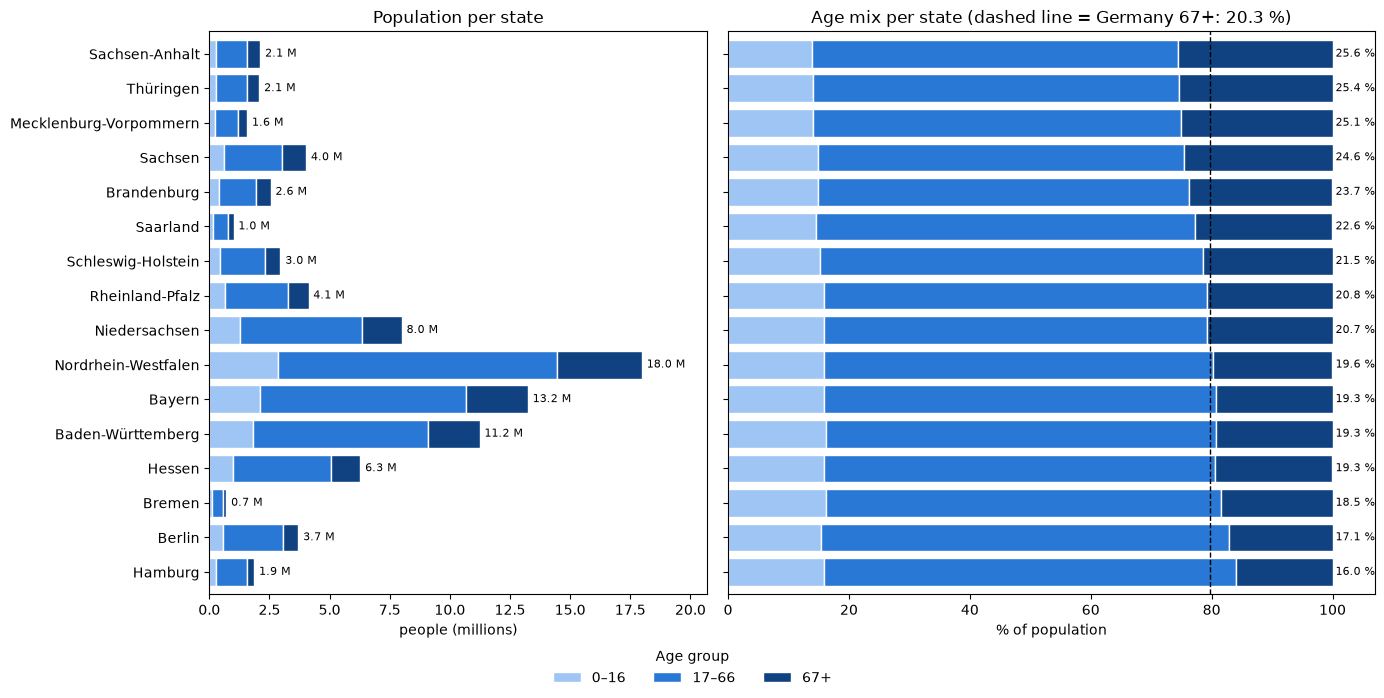

,no_licence_0_16,drivers_17_66,senior_drivers_67_plus,total,0–16 %,17–66 %,67+ %
state,,,,,,,
Hamburg,297486,1272697,299290,1869473,15.9,68.1,16.0
Berlin,571545,2497578,631454,3700577,15.4,67.5,17.1
Bremen,114553,461481,130881,706915,16.2,65.3,18.5
Hessen,999912,4064602,1214080,6278594,15.9,64.7,19.3
Baden-Württemberg,1825708,7246849,2166204,11238761,16.2,64.5,19.3
Bayern,2103040,8587821,2554642,13245503,15.9,64.8,19.3
Nordrhein-Westfalen,2868326,11585444,3532444,17986214,15.9,64.4,19.6
Niedersachsen,1264985,5078456,1657385,8000826,15.8,63.5,20.7
Rheinland-Pfalz,650225,2617119,855678,4123022,15.8,63.5,20.8


In [8]:
import matplotlib.pyplot as plt

AGE_GROUPS = {"no_licence_0_16": "0–16", "drivers_17_66": "17–66", "senior_drivers_67_plus": "67+"}
AGE_COLORS = ["#9ec5f4", "#2a78d6", "#104281"]

# 1. Table: only the 16 states (no Germany row), sorted by share 67+
age_by_state_df = pop_states_df.set_index("state")[list(AGE_GROUPS) + ["total"]].copy()
for col, label in AGE_GROUPS.items():
    age_by_state_df[f"{label} %"] = (age_by_state_df[col] / age_by_state_df["total"] * 100).round(1)
age_by_state_df = age_by_state_df.sort_values("67+ %")
germany_67_plus_pct = age_by_state_df["senior_drivers_67_plus"].sum() / age_by_state_df["total"].sum() * 100

# 2. Two charts side by side, same state order
fig, (ax_people, ax_pct) = plt.subplots(1, 2, figsize=(14, 7), sharey=True,
                                        gridspec_kw={"width_ratios": [1, 1.3]})

# Left: number of people (millions) per age group -> shows how different the states are in size
(age_by_state_df[list(AGE_GROUPS)] / 1e6).rename(columns=AGE_GROUPS).plot.barh(
    stacked=True, ax=ax_people, color=AGE_COLORS, width=0.8, edgecolor="white", legend=False)
for i, total in enumerate(age_by_state_df["total"]):
    ax_people.text(total / 1e6 + 0.2, i, f"{total / 1e6:.1f} M", va="center", fontsize=8)
ax_people.set(xlabel="people (millions)", ylabel="", title="Population per state")
ax_people.set_xlim(0, age_by_state_df["total"].max() / 1e6 * 1.15)

# Right: % per age group -> shows how old or young each state is
age_by_state_df[[f"{label} %" for label in AGE_GROUPS.values()]].plot.barh(
    stacked=True, ax=ax_pct, color=AGE_COLORS, width=0.8, edgecolor="white", legend=False)
for i, pct in enumerate(age_by_state_df["67+ %"]):
    ax_pct.text(100.5, i, f"{pct:.1f} %", va="center", fontsize=8)
ax_pct.axvline(100 - germany_67_plus_pct, color="black", ls="--", lw=1)
ax_pct.set(xlabel="% of population", xlim=(0, 107), title=f"Age mix per state (dashed line = Germany 67+: {germany_67_plus_pct:.1f} %)")

fig.legend(handles=ax_pct.get_legend_handles_labels()[0], labels=list(AGE_GROUPS.values()),
           title="Age group", frameon=False, loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

age_by_state_df

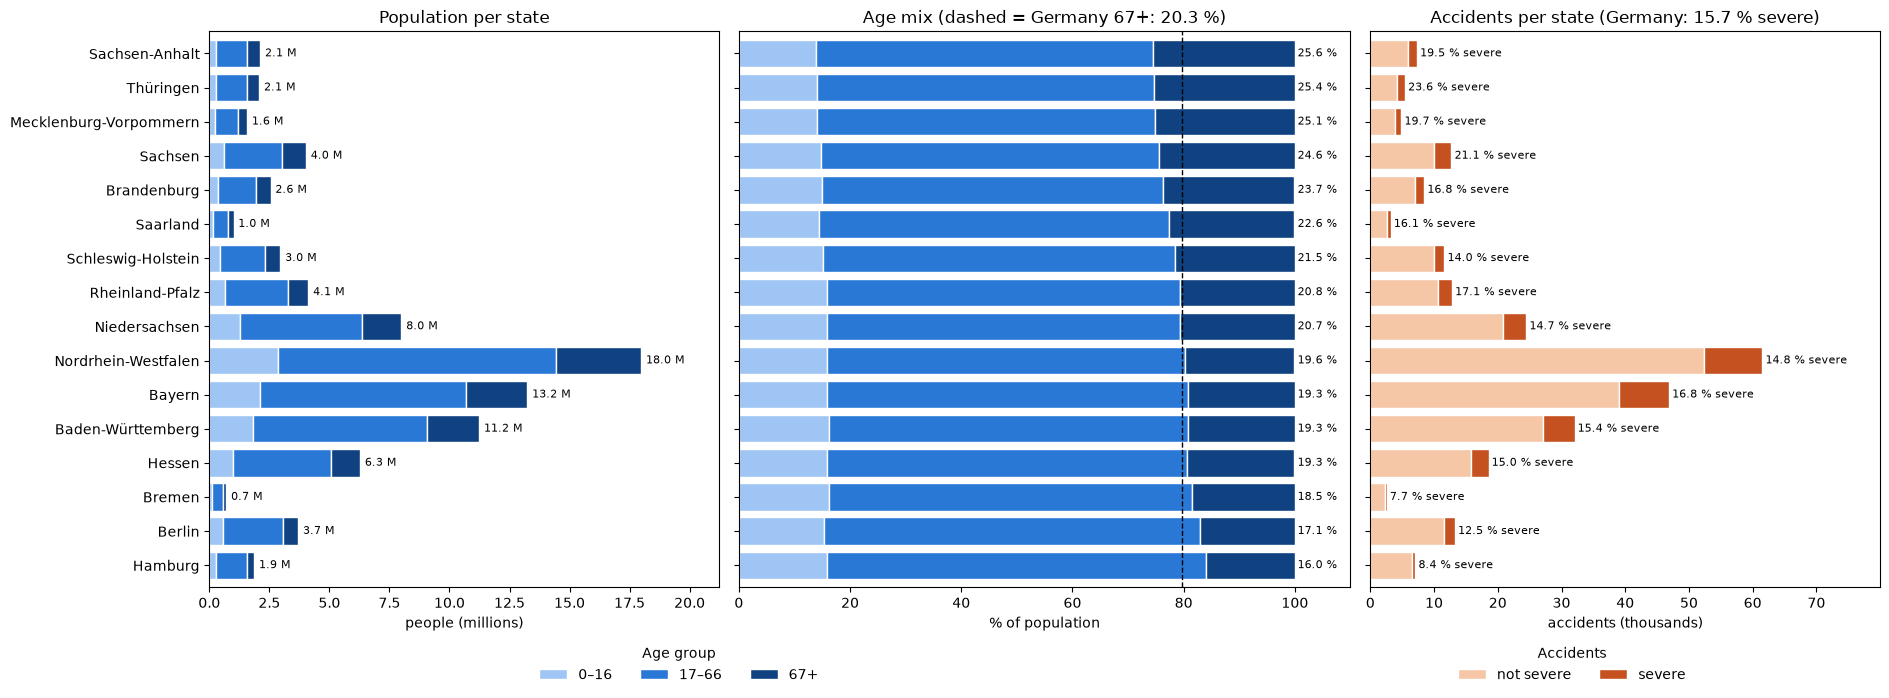

,no_licence_0_16,drivers_17_66,senior_drivers_67_plus,total,0–16 %,17–66 %,67+ %,accidents,not_severe,severe,severe_pct
state,,,,,,,,,,,
Hamburg,297486,1272697,299290,1869473,15.9,68.1,16.0,7057,6467,590,8.4
Berlin,571545,2497578,631454,3700577,15.4,67.5,17.1,13280,11620,1660,12.5
Bremen,114553,461481,130881,706915,16.2,65.3,18.5,2575,2377,198,7.7
Hessen,999912,4064602,1214080,6278594,15.9,64.7,19.3,18550,15771,2779,15.0
Baden-Württemberg,1825708,7246849,2166204,11238761,16.2,64.5,19.3,32042,27114,4928,15.4
Bayern,2103040,8587821,2554642,13245503,15.9,64.8,19.3,46869,38996,7873,16.8
Nordrhein-Westfalen,2868326,11585444,3532444,17986214,15.9,64.4,19.6,61521,52411,9110,14.8
Niedersachsen,1264985,5078456,1657385,8000826,15.8,63.5,20.7,24476,20879,3597,14.7
Rheinland-Pfalz,650225,2617119,855678,4123022,15.8,63.5,20.8,12815,10630,2185,17.1


In [9]:
import matplotlib.pyplot as plt

AGE_GROUPS = {"no_licence_0_16": "0–16", "drivers_17_66": "17–66", "senior_drivers_67_plus": "67+"}
AGE_COLORS = ["#9ec5f4", "#2a78d6", "#104281"]
SEVERITY_COLORS = ["#f6c7a6", "#c4511f"]          # not severe, severe

# 1. Population table (16 states, sorted by share 67+) + accidents per state
age_acc_df = pop_states_df.set_index("state")[list(AGE_GROUPS) + ["total"]].copy()
for col, label in AGE_GROUPS.items():
    age_acc_df[f"{label} %"] = (age_acc_df[col] / age_acc_df["total"] * 100).round(1)
age_acc_df = age_acc_df.join(state_compare_df.set_index("state")[["accidents", "not_severe", "severe", "severe_pct"]])
age_acc_df = age_acc_df.sort_values("67+ %")
germany_67_plus_share = age_acc_df["senior_drivers_67_plus"].sum() / age_acc_df["total"].sum() * 100
germany_severe_share = age_acc_df["severe"].sum() / age_acc_df["accidents"].sum() * 100

# 2. Three charts side by side, same state order
fig, (ax_people, ax_pct, ax_acc) = plt.subplots(1, 3, figsize=(19, 7), sharey=True,
                                                gridspec_kw={"width_ratios": [1, 1.2, 1]})

# Left: number of people (millions) per age group
(age_acc_df[list(AGE_GROUPS)] / 1e6).rename(columns=AGE_GROUPS).plot.barh(
    stacked=True, ax=ax_people, color=AGE_COLORS, width=0.8, edgecolor="white", legend=False)
for i, total in enumerate(age_acc_df["total"]):
    ax_people.text(total / 1e6 + 0.2, i, f"{total / 1e6:.1f} M", va="center", fontsize=8)
ax_people.set(xlabel="people (millions)", ylabel="", title="Population per state")
ax_people.set_xlim(0, age_acc_df["total"].max() / 1e6 * 1.18)

# Middle: % per age group
age_acc_df[[f"{label} %" for label in AGE_GROUPS.values()]].plot.barh(
    stacked=True, ax=ax_pct, color=AGE_COLORS, width=0.8, edgecolor="white", legend=False)
for i, pct in enumerate(age_acc_df["67+ %"]):
    ax_pct.text(100.5, i, f"{pct:.1f} %", va="center", fontsize=8)
ax_pct.axvline(100 - germany_67_plus_share, color="black", ls="--", lw=1)
ax_pct.set(xlabel="% of population", xlim=(0, 110),
           title=f"Age mix (dashed = Germany 67+: {germany_67_plus_share:.1f} %)")

# Right: accidents per state, not severe vs. severe (label = % severe)
(age_acc_df[["not_severe", "severe"]] / 1000).rename(columns={"not_severe": "not severe"}).plot.barh(
    stacked=True, ax=ax_acc, color=SEVERITY_COLORS, width=0.8, edgecolor="white", legend=False)
for i, (accidents, severe_pct) in enumerate(zip(age_acc_df["accidents"], age_acc_df["severe_pct"])):
    ax_acc.text(accidents / 1000 + 0.5, i, f"{severe_pct:.1f} % severe", va="center", fontsize=8)
ax_acc.set(xlabel="accidents (thousands)",
           title=f"Accidents per state (Germany: {germany_severe_share:.1f} % severe)")
ax_acc.set_xlim(0, age_acc_df["accidents"].max() / 1000 * 1.3)

# Legends under the charts
fig.legend(handles=ax_pct.get_legend_handles_labels()[0], labels=list(AGE_GROUPS.values()),
           title="Age group", frameon=False, loc="lower center", ncol=3, bbox_to_anchor=(0.36, 0))
fig.legend(handles=ax_acc.get_legend_handles_labels()[0], labels=["not severe", "severe"],
           title="Accidents", frameon=False, loc="lower center", ncol=2, bbox_to_anchor=(0.83, 0))
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

age_acc_df

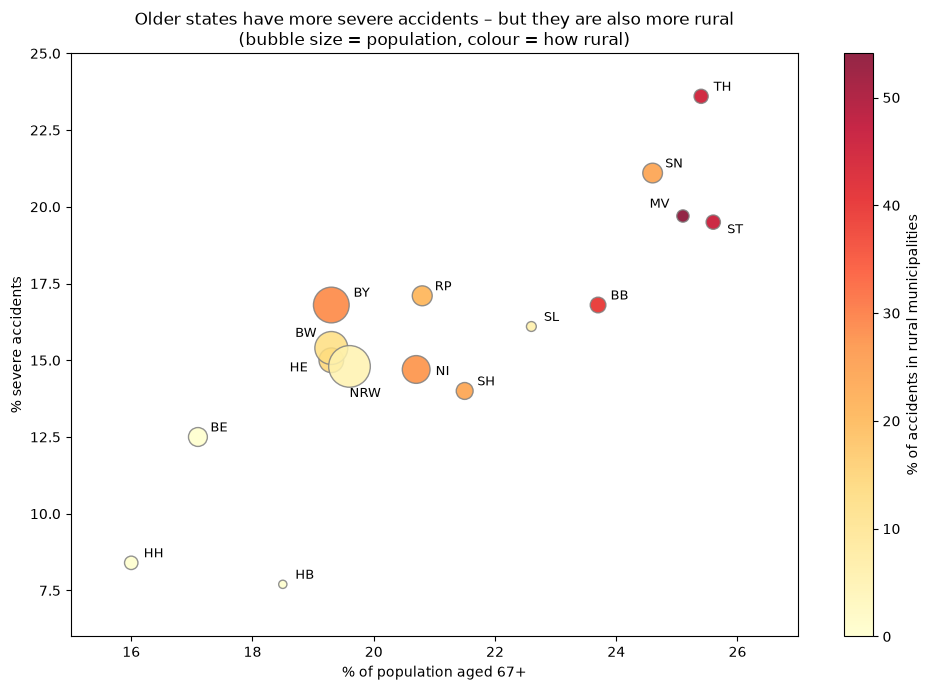

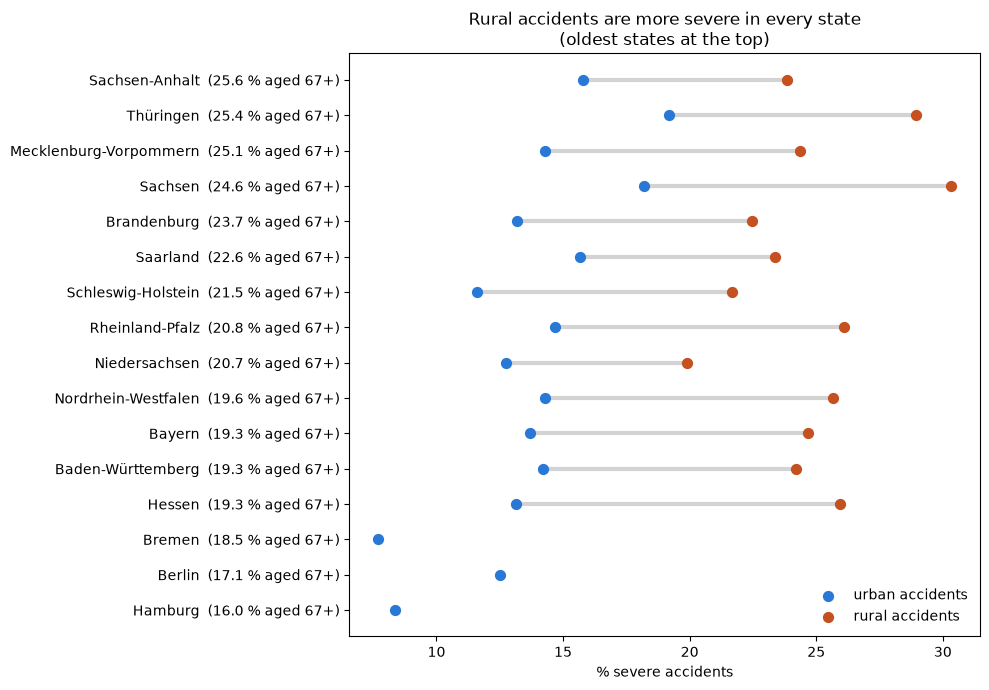

,state,total,senior_drivers_67_plus_pct,drivers_17_66_pct,severe_pct,rural_accidents_pct,severe_pct_rural,severe_pct_urban
ULAND,,,,,,,,
2,Hamburg,1869473,16.0,68.1,8.4,0.0,NaN,8.4
11,Berlin,3700577,17.1,67.5,12.5,0.0,NaN,12.5
4,Bremen,706915,18.5,65.3,7.7,0.0,NaN,7.7
6,Hessen,6278594,19.3,64.7,15.0,14.3,25.9,13.1
8,Baden-Württemberg,11238761,19.3,64.5,15.4,11.9,24.2,14.2
9,Bayern,13245503,19.3,64.8,16.8,28.3,24.7,13.7
5,Nordrhein-Westfalen,17986214,19.6,64.4,14.8,4.6,25.7,14.3
3,Niedersachsen,8000826,20.7,63.5,14.7,27.1,19.9,12.8
7,Rheinland-Pfalz,4123022,20.8,63.5,17.1,20.7,26.1,14.7


In [11]:
import matplotlib.pyplot as plt

# 1. Rural / urban per accident (by population density of the municipality)
RURAL_LIMIT = 150      # people per km²: below = rural municipality
acc_area_df = acc_df[["state", "severe", "population_per_km2"]].copy()
acc_area_df["area_type"] = (acc_area_df["population_per_km2"] < RURAL_LIMIT).map({True: "rural", False: "urban"})

# 2. Per state: share of rural accidents, and severe % separately for rural and urban accidents
rural_share = (acc_area_df.groupby("state")["area_type"].apply(lambda s: (s == "rural").mean() * 100)
               .rename("rural_accidents_pct"))
severe_by_area = (acc_area_df.groupby(["state", "area_type"])["severe"].mean().unstack() * 100).add_prefix("severe_pct_")

licence_severe_df = (pop_states_df.set_index("ULAND")[["state", "total", "senior_drivers_67_plus_pct", "drivers_17_66_pct"]]
                     .join(state_compare_df[["severe_pct"]]).join(rural_share).join(severe_by_area)
                     .sort_values("senior_drivers_67_plus_pct"))

# Short state names + label positions (offset in points) so labels don't overlap
STATE_SHORT = {1: "SH", 2: "HH", 3: "NI", 4: "HB", 5: "NRW", 6: "HE", 7: "RP", 8: "BW",
               9: "BY", 10: "SL", 11: "BE", 12: "BB", 13: "MV", 14: "SN", 15: "ST", 16: "TH"}
LABEL_OFFSET = {5: (0, -22), 6: (-30, -8), 8: (-26, 8), 9: (16, 6), 3: (14, -4), 13: (-24, 6), 15: (10, -8)}

# --- Chart 1: share 67+ vs. % severe (bubble size = population, colour = % rural accidents)
fig1, ax_bubble = plt.subplots(figsize=(10, 7))
bubbles = ax_bubble.scatter(licence_severe_df["senior_drivers_67_plus_pct"], licence_severe_df["severe_pct"],
                            s=licence_severe_df["total"] / 20_000, c=licence_severe_df["rural_accidents_pct"],
                            cmap="YlOrRd", edgecolor="grey", alpha=0.85)
for uland, row in licence_severe_df.iterrows():
    ax_bubble.annotate(STATE_SHORT[uland], (row["senior_drivers_67_plus_pct"], row["severe_pct"]),
                       xytext=LABEL_OFFSET.get(uland, (9, 4)), textcoords="offset points", fontsize=9)
fig1.colorbar(bubbles, ax=ax_bubble, label="% of accidents in rural municipalities")
ax_bubble.set(xlabel="% of population aged 67+", ylabel="% severe accidents", xlim=(15, 27), ylim=(6, 25),
              title="Older states have more severe accidents – but they are also more rural\n"
                    "(bubble size = population, colour = how rural)")
plt.tight_layout()
plt.show()

# --- Chart 2: severe % in urban vs. rural accidents per state (sorted by share 67+)
fig2, ax_split = plt.subplots(figsize=(10, 7))
y_pos = range(len(licence_severe_df))
ax_split.hlines(y_pos, licence_severe_df["severe_pct_urban"], licence_severe_df["severe_pct_rural"], color="lightgrey", lw=3)
ax_split.scatter(licence_severe_df["severe_pct_urban"], y_pos, color="#2a78d6", s=50, label="urban accidents", zorder=3)
ax_split.scatter(licence_severe_df["severe_pct_rural"], y_pos, color="#c4511f", s=50, label="rural accidents", zorder=3)
ax_split.set_yticks(list(y_pos))
ax_split.set_yticklabels([f"{s}  ({p:.1f} % aged 67+)" for s, p in
                          zip(licence_severe_df["state"], licence_severe_df["senior_drivers_67_plus_pct"])])
ax_split.set(xlabel="% severe accidents",
             title="Rural accidents are more severe in every state\n(oldest states at the top)")
ax_split.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

licence_severe_df.round(1)

Germany: 38.8 accidents and 6.1 severe accidents per 10,000 people aged 17+


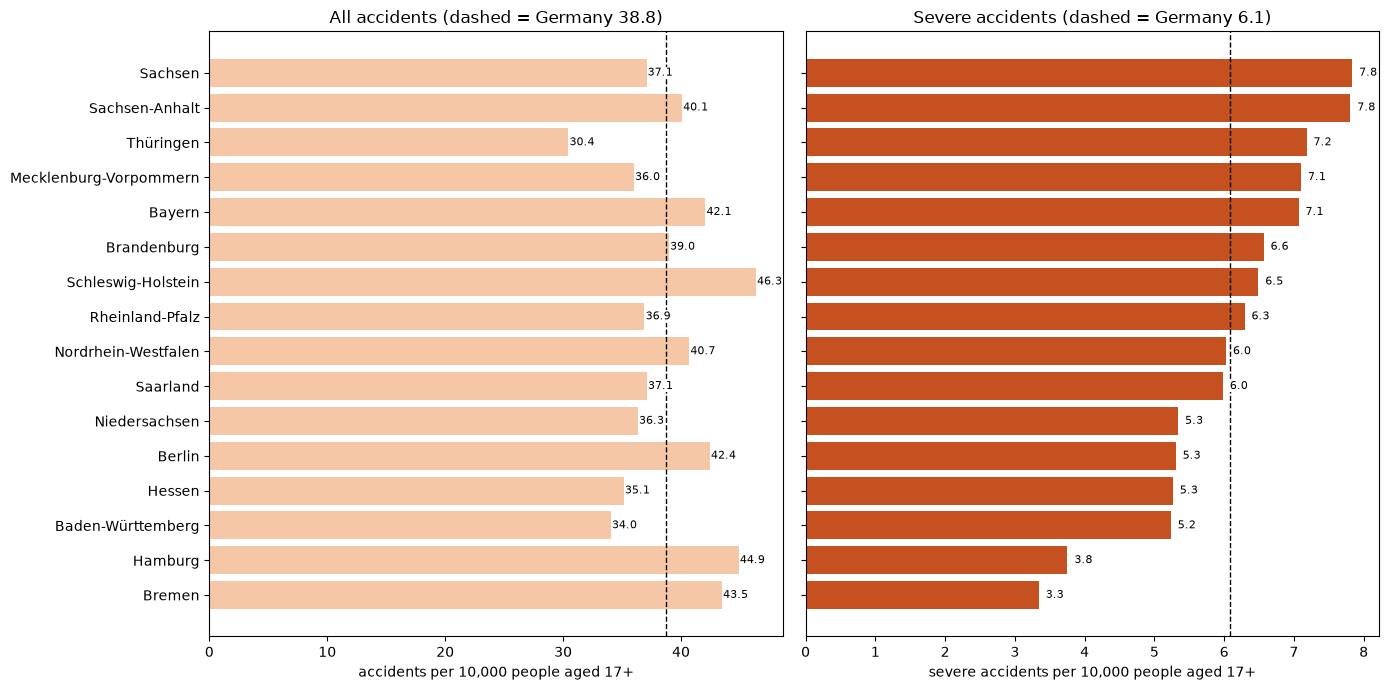

,state,driving_age_17_plus,accidents,severe,accidents_per_10k_17_plus,severe_per_10k_17_plus
ULAND,,,,,,
4,Bremen,592362,2575,198,43.5,3.3
2,Hamburg,1571987,7057,590,44.9,3.8
8,Baden-Württemberg,9413053,32042,4928,34.0,5.2
6,Hessen,5278682,18550,2779,35.1,5.3
11,Berlin,3129032,13280,1660,42.4,5.3
3,Niedersachsen,6735841,24476,3597,36.3,5.3
10,Saarland,861003,3194,515,37.1,6.0
5,Nordrhein-Westfalen,15117888,61521,9110,40.7,6.0
7,Rheinland-Pfalz,3472797,12815,2185,36.9,6.3


In [13]:
import matplotlib.pyplot as plt

licence_rate_df = state_compare_df[["state", "driving_age_17_plus", "accidents", "severe"]].copy()
licence_rate_df["accidents_per_10k_17_plus"] = licence_rate_df["accidents"] / licence_rate_df["driving_age_17_plus"] * 10_000
licence_rate_df["severe_per_10k_17_plus"] = licence_rate_df["severe"] / licence_rate_df["driving_age_17_plus"] * 10_000
licence_rate_df = licence_rate_df.sort_values("severe_per_10k_17_plus")

germany_acc_rate = licence_rate_df["accidents"].sum() / licence_rate_df["driving_age_17_plus"].sum() * 10_000
germany_severe_rate = licence_rate_df["severe"].sum() / licence_rate_df["driving_age_17_plus"].sum() * 10_000
print(f"Germany: {germany_acc_rate:.1f} accidents and {germany_severe_rate:.1f} severe accidents per 10,000 people aged 17+")

fig, (ax_all, ax_sev) = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
ax_all.barh(licence_rate_df["state"], licence_rate_df["accidents_per_10k_17_plus"], color="#f6c7a6")
ax_all.axvline(germany_acc_rate, color="black", ls="--", lw=1)
ax_all.set(xlabel="accidents per 10,000 people aged 17+",
           title=f"All accidents (dashed = Germany {germany_acc_rate:.1f})")
ax_sev.barh(licence_rate_df["state"], licence_rate_df["severe_per_10k_17_plus"], color="#c4511f")
ax_sev.axvline(germany_severe_rate, color="black", ls="--", lw=1)
ax_sev.set(xlabel="severe accidents per 10,000 people aged 17+",
           title=f"Severe accidents (dashed = Germany {germany_severe_rate:.1f})")
for ax, col in [(ax_all, "accidents_per_10k_17_plus"), (ax_sev, "severe_per_10k_17_plus")]:
    for i, value in enumerate(licence_rate_df[col]):
        ax.text(value + 0.1, i, f"{value:.1f}", va="center", fontsize=8,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
plt.tight_layout()
plt.show()

licence_rate_df.round(1)

Germany: 38.8 accidents and 6.1 severe accidents per 10,000 people aged 17+


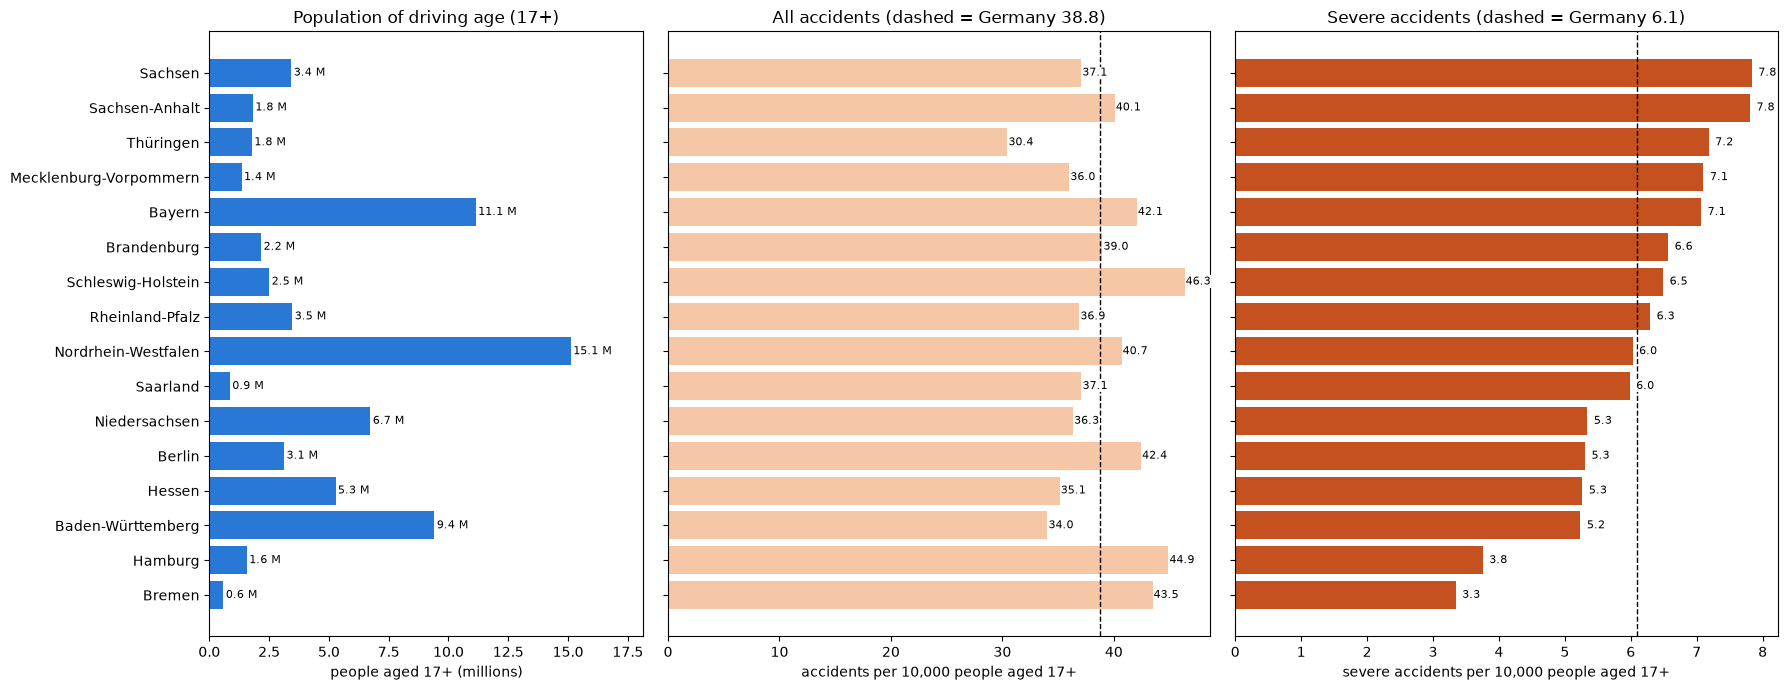

,state,driving_age_17_plus,accidents,severe,accidents_per_10k_17_plus,severe_per_10k_17_plus
ULAND,,,,,,
4,Bremen,592362,2575,198,43.5,3.3
2,Hamburg,1571987,7057,590,44.9,3.8
8,Baden-Württemberg,9413053,32042,4928,34.0,5.2
6,Hessen,5278682,18550,2779,35.1,5.3
11,Berlin,3129032,13280,1660,42.4,5.3
3,Niedersachsen,6735841,24476,3597,36.3,5.3
10,Saarland,861003,3194,515,37.1,6.0
5,Nordrhein-Westfalen,15117888,61521,9110,40.7,6.0
7,Rheinland-Pfalz,3472797,12815,2185,36.9,6.3


In [14]:
import matplotlib.pyplot as plt

licence_rate_df = state_compare_df[["state", "driving_age_17_plus", "accidents", "severe"]].copy()
licence_rate_df["accidents_per_10k_17_plus"] = licence_rate_df["accidents"] / licence_rate_df["driving_age_17_plus"] * 10_000
licence_rate_df["severe_per_10k_17_plus"] = licence_rate_df["severe"] / licence_rate_df["driving_age_17_plus"] * 10_000
licence_rate_df = licence_rate_df.sort_values("severe_per_10k_17_plus")

germany_acc_rate = licence_rate_df["accidents"].sum() / licence_rate_df["driving_age_17_plus"].sum() * 10_000
germany_severe_rate = licence_rate_df["severe"].sum() / licence_rate_df["driving_age_17_plus"].sum() * 10_000
print(f"Germany: {germany_acc_rate:.1f} accidents and {germany_severe_rate:.1f} severe accidents per 10,000 people aged 17+")

LABEL_BOX = dict(facecolor="white", edgecolor="none", pad=0.5)
fig, (ax_pop, ax_all, ax_sev) = plt.subplots(1, 3, figsize=(18, 7), sharey=True,
                                             gridspec_kw={"width_ratios": [0.8, 1, 1]})

# Left: how many people aged 17+ live in each state (millions)
ax_pop.barh(licence_rate_df["state"], licence_rate_df["driving_age_17_plus"] / 1e6, color="#2a78d6")
ax_pop.set(xlabel="people aged 17+ (millions)", title="Population of driving age (17+)")
ax_pop.set_xlim(0, licence_rate_df["driving_age_17_plus"].max() / 1e6 * 1.2)
for i, value in enumerate(licence_rate_df["driving_age_17_plus"] / 1e6):
    ax_pop.text(value + 0.1, i, f"{value:.1f} M", va="center", fontsize=8, bbox=LABEL_BOX)

# Middle: all accidents per 10,000 people aged 17+
ax_all.barh(licence_rate_df["state"], licence_rate_df["accidents_per_10k_17_plus"], color="#f6c7a6")
ax_all.axvline(germany_acc_rate, color="black", ls="--", lw=1)
ax_all.set(xlabel="accidents per 10,000 people aged 17+",
           title=f"All accidents (dashed = Germany {germany_acc_rate:.1f})")

# Right: severe accidents per 10,000 people aged 17+
ax_sev.barh(licence_rate_df["state"], licence_rate_df["severe_per_10k_17_plus"], color="#c4511f")
ax_sev.axvline(germany_severe_rate, color="black", ls="--", lw=1)
ax_sev.set(xlabel="severe accidents per 10,000 people aged 17+",
           title=f"Severe accidents (dashed = Germany {germany_severe_rate:.1f})")

for ax, col in [(ax_all, "accidents_per_10k_17_plus"), (ax_sev, "severe_per_10k_17_plus")]:
    for i, value in enumerate(licence_rate_df[col]):
        ax.text(value + 0.1, i, f"{value:.1f}", va="center", fontsize=8, bbox=LABEL_BOX)
plt.tight_layout()
plt.show()

licence_rate_df.round(1)

Accidents with only car / motorcycle / truck: 133,187 of 272,812 (48.8%) | severe: 15.9% (all accidents: 15.7%)


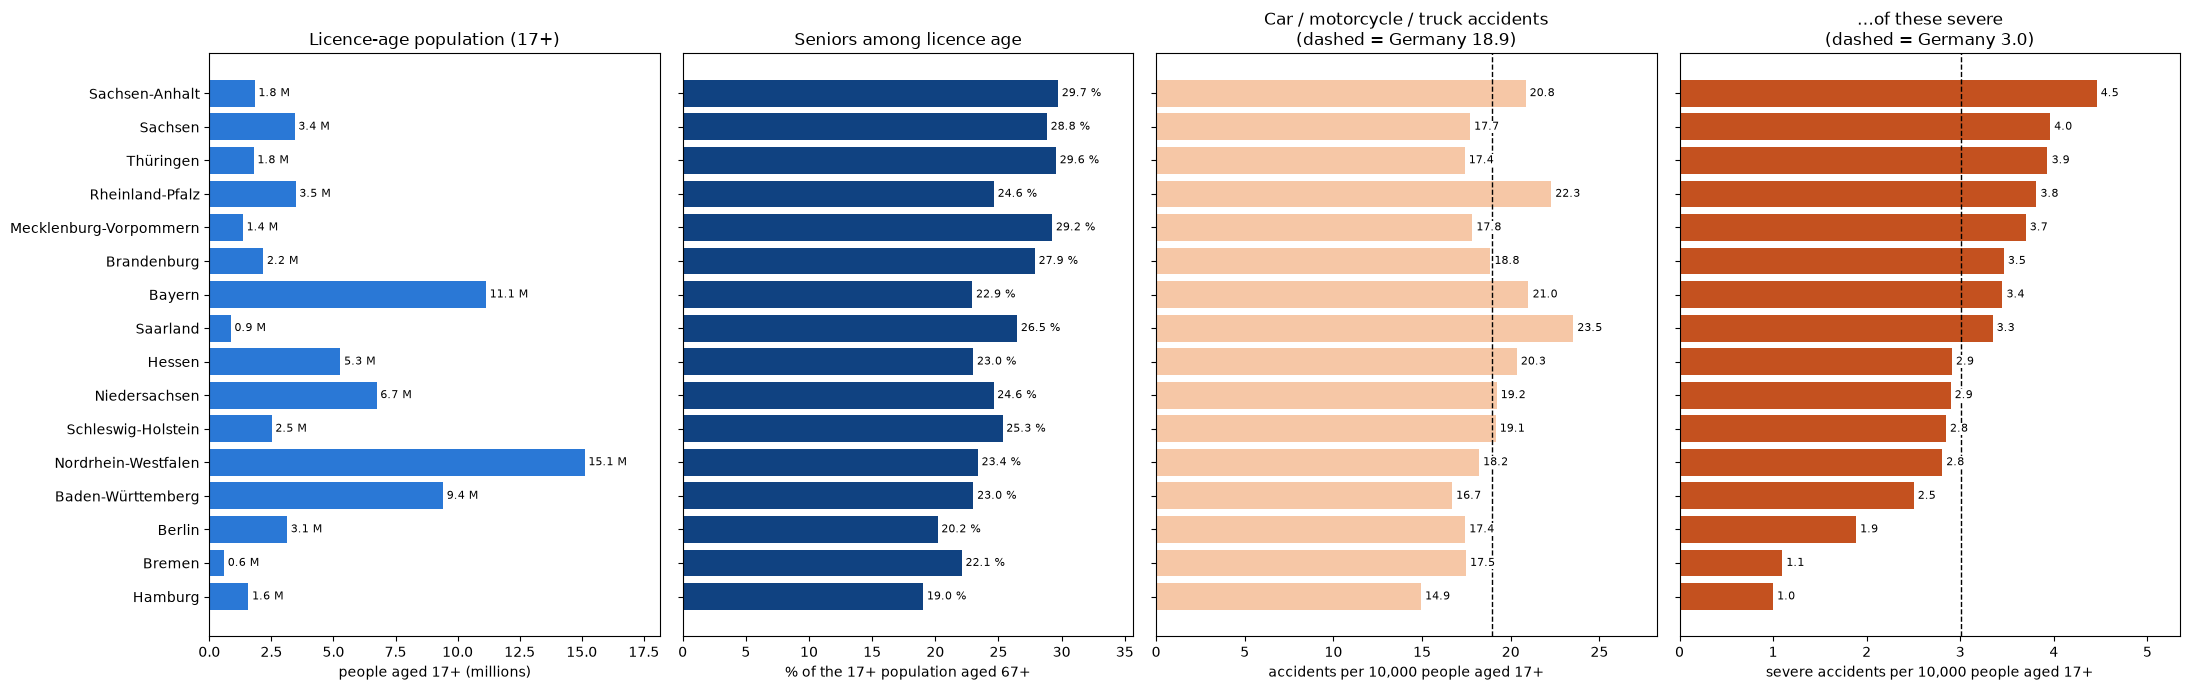

,state,driving_age_17_plus,senior_share_of_17_plus_pct,motor_accidents,motor_severe,motor_severe_pct,with_car,with_motorcycle,with_truck,motor_per_10k_17_plus,motor_severe_per_10k_17_plus,motorcycle_per_10k_17_plus
ULAND,,,,,,,,,,,,
2,Hamburg,1571987,19.0,2348,157,6.7,2165,523,222,14.9,1.0,3.3
4,Bremen,592362,22.1,1035,65,6.3,988,142,86,17.5,1.1,2.4
11,Berlin,3129032,20.2,5453,590,10.8,5101,1730,229,17.4,1.9,5.5
8,Baden-Württemberg,9413053,23.0,15707,2355,15.0,13668,4368,969,16.7,2.5,4.6
5,Nordrhein-Westfalen,15117888,23.4,27527,4242,15.4,24587,6995,1632,18.2,2.8,4.6
1,Schleswig-Holstein,2508885,25.3,4804,714,14.9,4262,1060,269,19.1,2.8,4.2
3,Niedersachsen,6735841,24.6,12933,1951,15.1,11798,2270,976,19.2,2.9,3.4
6,Hessen,5278682,23.0,10735,1536,14.3,9731,2310,677,20.3,2.9,4.4
10,Saarland,861003,26.5,2025,288,14.2,1827,435,86,23.5,3.3,5.1


In [15]:
import matplotlib.pyplot as plt

# 1. Accidents with ONLY licence vehicles: car / motorcycle / truck, no bicycle, pedestrian or other vehicle
licence_only_mask = ((acc_df[["car", "motorcycle", "truck"]].sum(axis=1) > 0)
                     & (acc_df[["bicycle", "pedestrian", "other_vehicle"]].sum(axis=1) == 0))
motor_acc_df = acc_df[licence_only_mask].copy()
print(f"Accidents with only car / motorcycle / truck: {len(motor_acc_df):,} of {len(acc_df):,} "
      f"({len(motor_acc_df) / len(acc_df):.1%}) | severe: {motor_acc_df['severe'].mean():.1%} "
      f"(all accidents: {acc_df['severe'].mean():.1%})")

# 2. Per state: these accidents, severe, and which vehicles were involved
motor_state_df = motor_acc_df.groupby("state").agg(
    motor_accidents=("accident_id", "size"), motor_severe=("severe", "sum"),
    with_car=("car", "sum"), with_motorcycle=("motorcycle", "sum"), with_truck=("truck", "sum"))
motor_state_df["motor_severe_pct"] = motor_state_df["motor_severe"] / motor_state_df["motor_accidents"] * 100

# 3. Combine with population of licence age (17+) and the share of seniors (67+)
motor_pop_df = (pop_states_df.set_index("ULAND")[["state", "drivers_17_66", "senior_drivers_67_plus",
                                                  "senior_drivers_67_plus_pct"]].join(motor_state_df))
motor_pop_df["driving_age_17_plus"] = motor_pop_df["drivers_17_66"] + motor_pop_df["senior_drivers_67_plus"]
motor_pop_df["senior_share_of_17_plus_pct"] = motor_pop_df["senior_drivers_67_plus"] / motor_pop_df["driving_age_17_plus"] * 100
motor_pop_df["motor_per_10k_17_plus"] = motor_pop_df["motor_accidents"] / motor_pop_df["driving_age_17_plus"] * 10_000
motor_pop_df["motor_severe_per_10k_17_plus"] = motor_pop_df["motor_severe"] / motor_pop_df["driving_age_17_plus"] * 10_000
motor_pop_df["motorcycle_per_10k_17_plus"] = motor_pop_df["with_motorcycle"] / motor_pop_df["driving_age_17_plus"] * 10_000
motor_pop_df = motor_pop_df.sort_values("motor_severe_per_10k_17_plus")

germany_motor_rate = motor_pop_df["motor_accidents"].sum() / motor_pop_df["driving_age_17_plus"].sum() * 10_000
germany_motor_severe_rate = motor_pop_df["motor_severe"].sum() / motor_pop_df["driving_age_17_plus"].sum() * 10_000

# 4. Four charts, same state order (sorted by severe accidents per 10,000 people aged 17+)
LABEL_BOX = dict(facecolor="white", edgecolor="none", pad=0.5)
fig, axes = plt.subplots(1, 4, figsize=(22, 7), sharey=True, gridspec_kw={"width_ratios": [0.9, 0.9, 1, 1]})
panels = [
    ("driving_age_17_plus", 1e6, "#2a78d6", "people aged 17+ (millions)", "Licence-age population (17+)", "{:.1f} M", None),
    ("senior_share_of_17_plus_pct", 1, "#104281", "% of the 17+ population aged 67+", "Seniors among licence age", "{:.1f} %", None),
    ("motor_per_10k_17_plus", 1, "#f6c7a6", "accidents per 10,000 people aged 17+",
     f"Car / motorcycle / truck accidents\n(dashed = Germany {germany_motor_rate:.1f})", "{:.1f}", germany_motor_rate),
    ("motor_severe_per_10k_17_plus", 1, "#c4511f", "severe accidents per 10,000 people aged 17+",
     f"…of these severe\n(dashed = Germany {germany_motor_severe_rate:.1f})", "{:.1f}", germany_motor_severe_rate),
]
for ax, (col, divisor, color, xlabel, title, fmt, germany_line) in zip(axes, panels):
    values = motor_pop_df[col] / divisor
    ax.barh(motor_pop_df["state"], values, color=color)
    ax.set(xlabel=xlabel, title=title)
    ax.set_xlim(0, values.max() * 1.2)
    if germany_line is not None:
        ax.axvline(germany_line, color="black", ls="--", lw=1)
    for i, value in enumerate(values):
        ax.text(value + values.max() * 0.01, i, fmt.format(value), va="center", fontsize=8, bbox=LABEL_BOX)
plt.tight_layout()
plt.show()

motor_pop_df[["state", "driving_age_17_plus", "senior_share_of_17_plus_pct", "motor_accidents", "motor_severe",
              "motor_severe_pct", "with_car", "with_motorcycle", "with_truck",
              "motor_per_10k_17_plus", "motor_severe_per_10k_17_plus", "motorcycle_per_10k_17_plus"]].round(1)

Accidents with a bicycle: 89,508 of 272,812 (32.8%) | severe: 15.0% (all accidents: 15.7%)


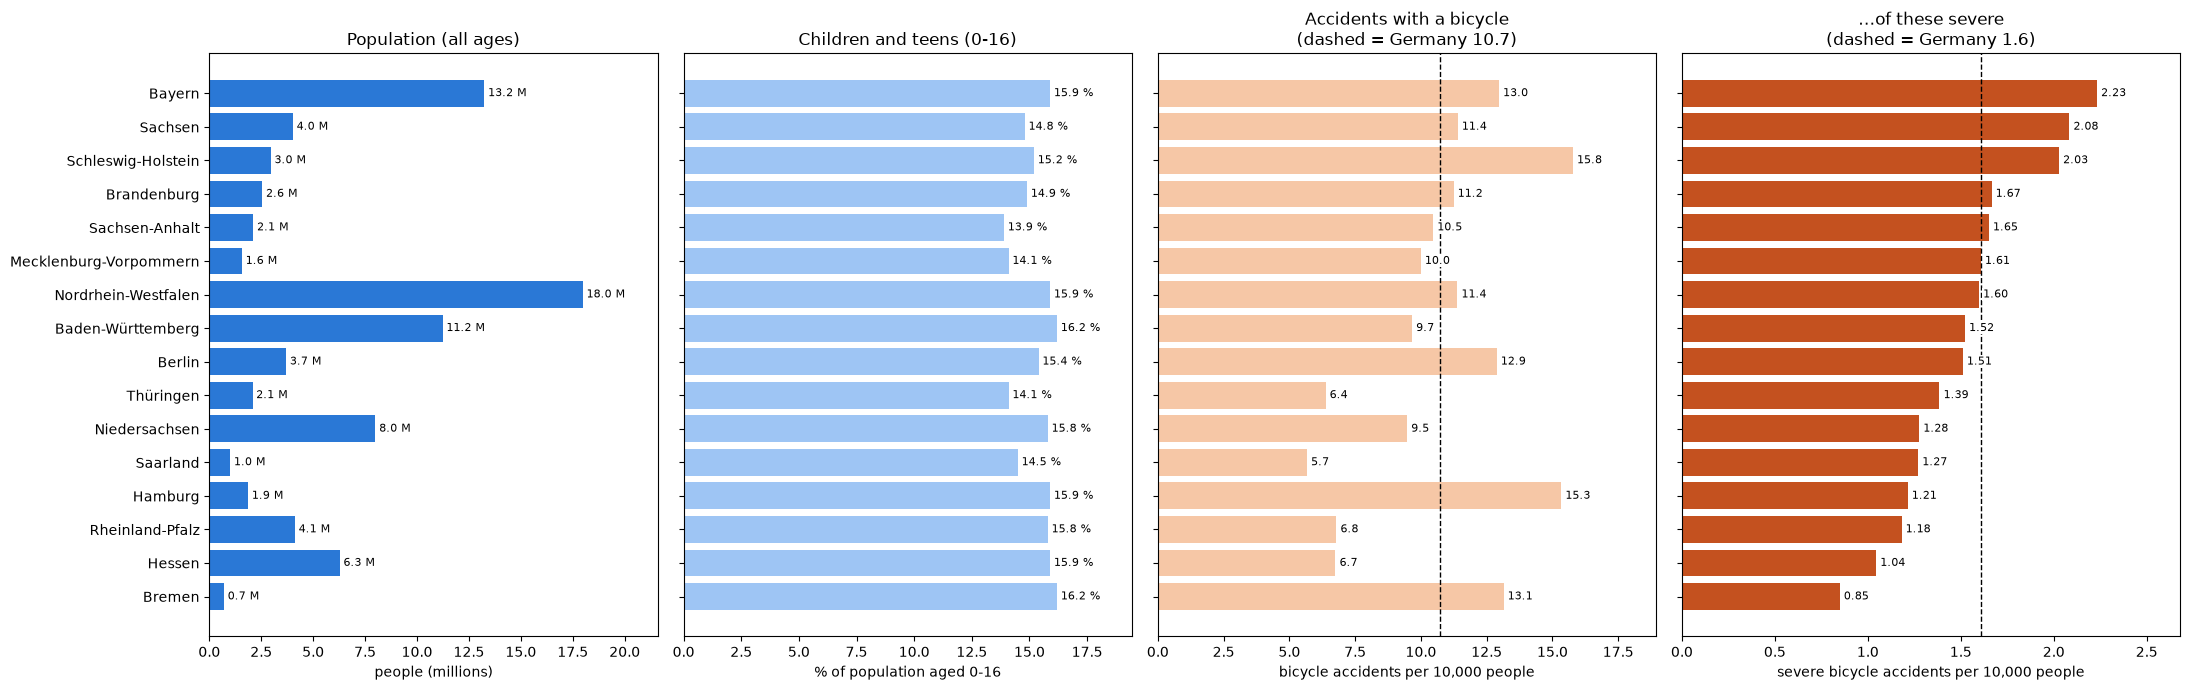

,state,total,no_licence_0_16,no_licence_0_16_pct,bike_accidents,bike_severe,bike_severe_pct,bike_per_10k_people,bike_severe_per_10k_people,bike_severe_per_10k_under_17
ULAND,,,,,,,,,,
4,Bremen,706915,114553,16.2,929,60,6.46,13.14,0.85,5.24
6,Hessen,6278594,999912,15.9,4238,656,15.48,6.75,1.04,6.56
7,Rheinland-Pfalz,4123022,650225,15.8,2797,487,17.41,6.78,1.18,7.49
2,Hamburg,1869473,297486,15.9,2867,227,7.92,15.34,1.21,7.63
10,Saarland,1007342,146339,14.5,571,128,22.42,5.67,1.27,8.75
3,Niedersachsen,8000826,1264985,15.8,7581,1021,13.47,9.48,1.28,8.07
16,Thüringen,2078946,293726,14.1,1325,288,21.74,6.37,1.39,9.81
11,Berlin,3700577,571545,15.4,4767,559,11.73,12.88,1.51,9.78
8,Baden-Württemberg,11238761,1825708,16.2,10861,1711,15.75,9.66,1.52,9.37


In [16]:
import matplotlib.pyplot as plt

# 1. All accidents with at least one bicycle involved
bike_acc_df = acc_df[acc_df["bicycle"] == 1].copy()
print(f"Accidents with a bicycle: {len(bike_acc_df):,} of {len(acc_df):,} ({len(bike_acc_df) / len(acc_df):.1%}) "
      f"| severe: {bike_acc_df['severe'].mean():.1%} (all accidents: {acc_df['severe'].mean():.1%})")

# 2. Per state: bicycle accidents and severe bicycle accidents
bike_state_df = bike_acc_df.groupby("state").agg(bike_accidents=("accident_id", "size"), bike_severe=("severe", "sum"))
bike_state_df["bike_severe_pct"] = bike_state_df["bike_severe"] / bike_state_df["bike_accidents"] * 100

# 3. Combine with population: all ages and children/teens under 17 (0-16)
bike_pop_df = pop_states_df.set_index("ULAND")[["state", "total", "no_licence_0_16", "no_licence_0_16_pct"]].join(bike_state_df)
bike_pop_df["bike_per_10k_people"] = bike_pop_df["bike_accidents"] / bike_pop_df["total"] * 10_000
bike_pop_df["bike_severe_per_10k_people"] = bike_pop_df["bike_severe"] / bike_pop_df["total"] * 10_000
bike_pop_df["bike_severe_per_10k_under_17"] = bike_pop_df["bike_severe"] / bike_pop_df["no_licence_0_16"] * 10_000
bike_pop_df = bike_pop_df.sort_values("bike_severe_per_10k_people")

germany_bike_rate = bike_pop_df["bike_accidents"].sum() / bike_pop_df["total"].sum() * 10_000
germany_bike_severe_rate = bike_pop_df["bike_severe"].sum() / bike_pop_df["total"].sum() * 10_000

# 4. Four charts, same state order (sorted by severe bicycle accidents per 10,000 people)
LABEL_BOX = dict(facecolor="white", edgecolor="none", pad=0.5)
fig, axes = plt.subplots(1, 4, figsize=(22, 7), sharey=True, gridspec_kw={"width_ratios": [0.9, 0.9, 1, 1]})
panels = [
    ("total", 1e6, "#2a78d6", "people (millions)", "Population (all ages)", "{:.1f} M", None),
    ("no_licence_0_16_pct", 1, "#9ec5f4", "% of population aged 0-16", "Children and teens (0-16)", "{:.1f} %", None),
    ("bike_per_10k_people", 1, "#f6c7a6", "bicycle accidents per 10,000 people",
     f"Accidents with a bicycle\n(dashed = Germany {germany_bike_rate:.1f})", "{:.1f}", germany_bike_rate),
    ("bike_severe_per_10k_people", 1, "#c4511f", "severe bicycle accidents per 10,000 people",
     f"…of these severe\n(dashed = Germany {germany_bike_severe_rate:.1f})", "{:.2f}", germany_bike_severe_rate),
]
for ax, (col, divisor, color, xlabel, title, fmt, germany_line) in zip(axes, panels):
    values = bike_pop_df[col] / divisor
    ax.barh(bike_pop_df["state"], values, color=color)
    ax.set(xlabel=xlabel, title=title)
    ax.set_xlim(0, values.max() * 1.2)
    if germany_line is not None:
        ax.axvline(germany_line, color="black", ls="--", lw=1)
    for i, value in enumerate(values):
        ax.text(value + values.max() * 0.01, i, fmt.format(value), va="center", fontsize=8, bbox=LABEL_BOX)
plt.tight_layout()
plt.show()

bike_pop_df[["state", "total", "no_licence_0_16", "no_licence_0_16_pct", "bike_accidents", "bike_severe",
             "bike_severe_pct", "bike_per_10k_people", "bike_severe_per_10k_people",
             "bike_severe_per_10k_under_17"]].round(2)

urbanisation
dicht besiedelt                urban (densely populated)
gering besiedelt              rural (sparsely populated)
mittlere Besiedlungsdichte                towns (medium)
Name: area_type, dtype: str 

accidents without area type: 0
                            accidents  severe_pct  share_of_accidents_pct
area_type                                                                
urban (densely populated)      109896        11.3                    40.3
towns (medium)                 113257        16.2                    41.5
rural (sparsely populated)      49659        24.3                    18.2


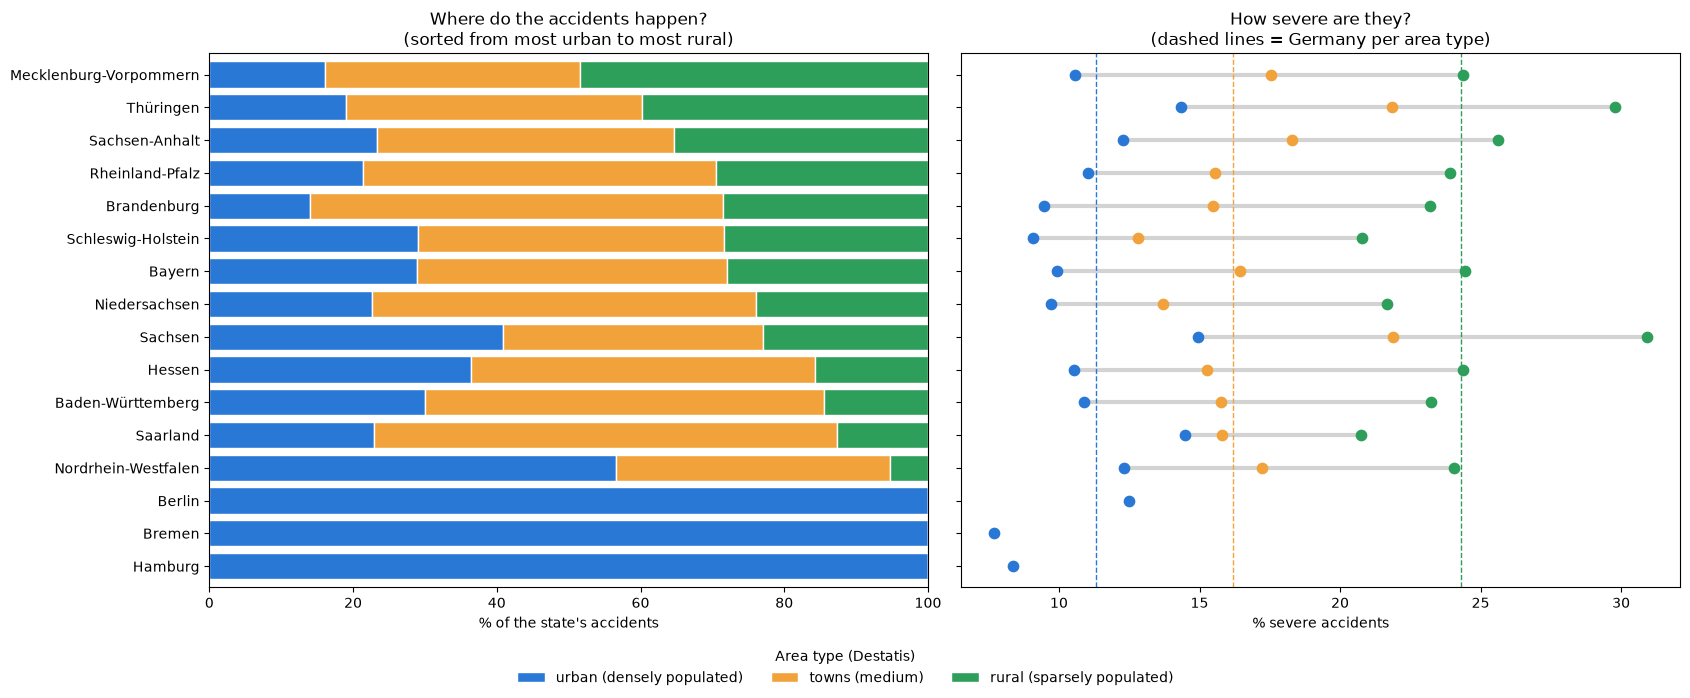

area_type,urban (densely populated),towns (medium),rural (sparsely populated)
state,,,
Hamburg,8.4,NaN,NaN
Bremen,7.7,NaN,NaN
Berlin,12.5,NaN,NaN
Nordrhein-Westfalen,12.3,17.2,24.1
Saarland,14.5,15.8,20.7
Baden-Württemberg,10.9,15.8,23.2
Hessen,10.5,15.3,24.4
Sachsen,15.0,21.9,30.9
Niedersachsen,9.7,13.7,21.7


In [21]:
import matplotlib.pyplot as plt

# 1. Official urbanisation per municipality (Destatis list, saved in zb01) -> add to every accident
city_urban_df = pd.read_csv("city_accidents_2025.csv", dtype={"ags": str})[["ags", "urbanisation"]]

# Map the original text to 3 groups ("mitt" first: "mittlere Besiedlungsdichte" also contains "dicht")
def urban_group(text):
    text = str(text).lower()
    if "mitt" in text:
        return "towns (medium)"
    if "dicht" in text:
        return "urban (densely populated)"
    if "gering" in text or "dünn" in text:
        return "rural (sparsely populated)"
    return None

city_urban_df["area_type"] = city_urban_df["urbanisation"].map(urban_group)
print(city_urban_df.groupby("urbanisation")["area_type"].first(), "\n")      # check: each original value -> its group

URBAN_ORDER = ["urban (densely populated)", "towns (medium)", "rural (sparsely populated)"]
URBAN_COLORS = ["#2a78d6", "#f2a23a", "#2e9e5b"]
missing_groups = set(URBAN_ORDER) - set(city_urban_df["area_type"].dropna())
assert not missing_groups, f"Empty group(s): {missing_groups} - check the mapping above"

acc_urban_df = acc_df[["state", "severe", "ags"]].copy()
acc_urban_df["ags"] = acc_urban_df["ags"].astype(str).str.zfill(8)
acc_urban_df = acc_urban_df.merge(city_urban_df[["ags", "area_type"]], on="ags", how="left", validate="many_to_one")
print("accidents without area type:", acc_urban_df["area_type"].isna().sum())     # expected: 0 (or 1)

# 2. Germany overview: accidents and % severe per area type
germany_urban_df = (acc_urban_df.groupby("area_type")["severe"].agg(accidents="size", severe_pct="mean")
                    .reindex(URBAN_ORDER))
germany_urban_df["severe_pct"] = (germany_urban_df["severe_pct"] * 100).round(1)
germany_urban_df["share_of_accidents_pct"] = (germany_urban_df["accidents"] / germany_urban_df["accidents"].sum() * 100).round(1)
print(germany_urban_df)

# 3. Per state: share of accidents per area type, and % severe per area type
state_names = pop_states_df.set_index("ULAND")["state"]
urban_share_df = (pd.crosstab(acc_urban_df["state"], acc_urban_df["area_type"], normalize="index")
                  .reindex(columns=URBAN_ORDER, fill_value=0) * 100)
urban_severe_df = (acc_urban_df.groupby(["state", "area_type"])["severe"].mean().unstack()
                   .reindex(columns=URBAN_ORDER) * 100)
state_order = urban_share_df.sort_values("rural (sparsely populated)").index      # most urban -> most rural
urban_share_df = urban_share_df.loc[state_order].rename(index=state_names)
urban_severe_df = urban_severe_df.loc[state_order].rename(index=state_names)

# 4. Two charts, same state order
fig, (ax_share, ax_sev) = plt.subplots(1, 2, figsize=(17, 7), sharey=True)

# Left: where do the accidents happen? (% of each state's accidents per area type)
urban_share_df.plot.barh(stacked=True, ax=ax_share, color=URBAN_COLORS, width=0.8, edgecolor="white", legend=False)
ax_share.set(xlabel="% of the state's accidents", ylabel="", xlim=(0, 100),
             title="Where do the accidents happen?\n(sorted from most urban to most rural)")

# Right: how severe are they? (% severe per area type)
y_pos = range(len(urban_severe_df))
ax_sev.hlines(y_pos, urban_severe_df.min(axis=1), urban_severe_df.max(axis=1), color="lightgrey", lw=3)
for level, color in zip(URBAN_ORDER, URBAN_COLORS):
    ax_sev.scatter(urban_severe_df[level], y_pos, color=color, s=55, zorder=3)
    ax_sev.axvline(germany_urban_df.loc[level, "severe_pct"], color=color, ls="--", lw=1)
ax_sev.set(xlabel="% severe accidents", title="How severe are they?\n(dashed lines = Germany per area type)")

fig.legend(handles=ax_share.get_legend_handles_labels()[0], labels=URBAN_ORDER,
           title="Area type (Destatis)", frameon=False, loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

urban_severe_df.round(1)

Correlations between the 16 states:
                            senior_drivers_67_plus_pct  rural_population_pct  \
senior_drivers_67_plus_pct                        1.00                  0.81   
rural_population_pct                              0.81                  1.00   
severe_pct                                        0.85                  0.80   

                            severe_pct  
senior_drivers_67_plus_pct        0.85  
rural_population_pct              0.80  
severe_pct                        1.00   



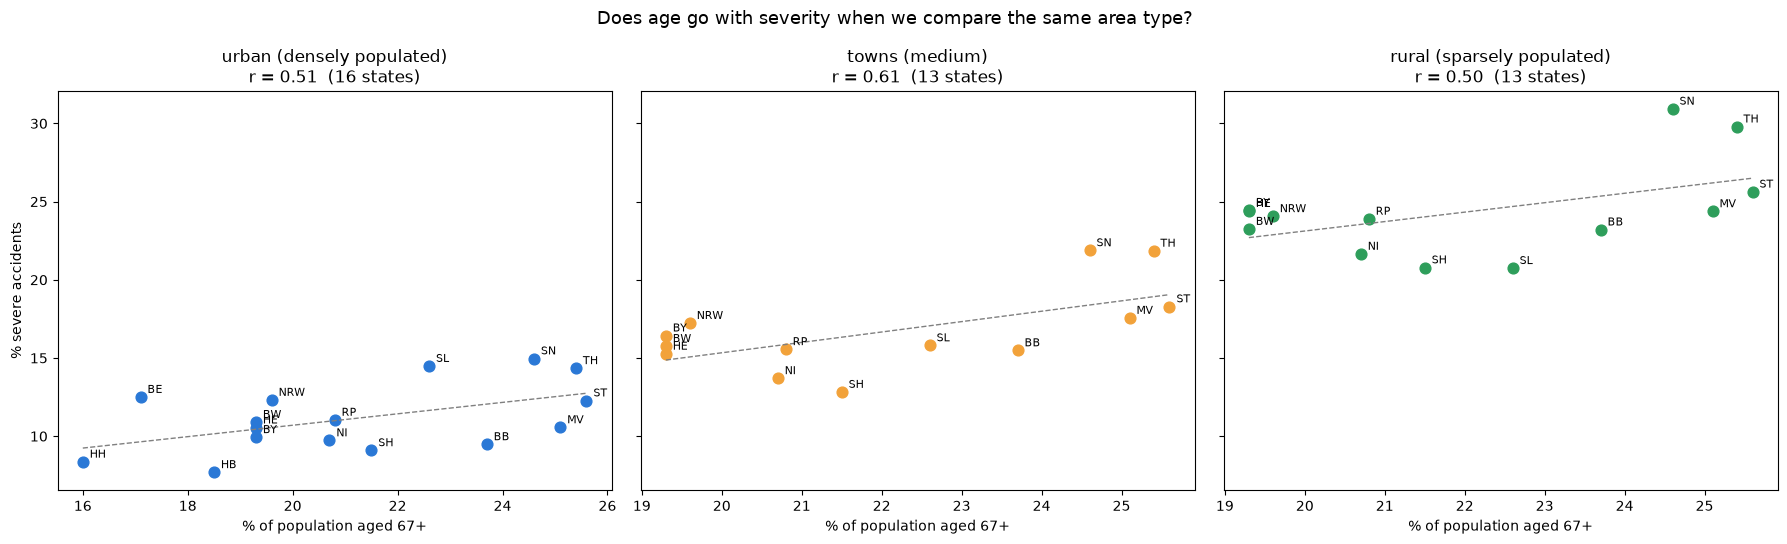

,senior_drivers_67_plus_pct,no_licence_0_16_pct,rural_population_pct,severe_pct,urban (densely populated),towns (medium),rural (sparsely populated)
state,,,,,,,
Schleswig-Holstein,21.5,15.2,26.5,14.0,9.1,12.8,20.8
Hamburg,16.0,15.9,0.0,8.4,8.4,NaN,NaN
Niedersachsen,20.7,15.8,26.3,14.7,9.7,13.7,21.7
Bremen,18.5,16.2,0.0,7.7,7.7,NaN,NaN
Nordrhein-Westfalen,19.6,15.9,6.0,14.8,12.3,17.2,24.1
Hessen,19.3,15.9,17.1,15.0,10.5,15.3,24.4
Rheinland-Pfalz,20.8,15.8,27.3,17.1,11.0,15.6,23.9
Baden-Württemberg,19.3,16.2,15.8,15.4,10.9,15.8,23.2
Bayern,19.3,15.9,30.1,16.8,9.9,16.4,24.5


In [22]:
import numpy as np
import matplotlib.pyplot as plt

STATE_SHORT_BY_NAME = {"Schleswig-Holstein": "SH", "Hamburg": "HH", "Niedersachsen": "NI", "Bremen": "HB",
                       "Nordrhein-Westfalen": "NRW", "Hessen": "HE", "Rheinland-Pfalz": "RP", "Baden-Württemberg": "BW",
                       "Bayern": "BY", "Saarland": "SL", "Berlin": "BE", "Brandenburg": "BB",
                       "Mecklenburg-Vorpommern": "MV", "Sachsen": "SN", "Sachsen-Anhalt": "ST", "Thüringen": "TH"}

# 1. Per state: age (from licence file) + how rural the population is + severe %
age_by_state = pop_states_df.set_index("state")[["senior_drivers_67_plus_pct", "no_licence_0_16_pct"]]

# Share of the state's population living in rural municipalities (municipalities with accidents, one row each)
muni_pop_df = (acc_df[["state", "ags", "population"]].drop_duplicates("ags")
               .assign(ags=lambda d: d["ags"].astype(str).str.zfill(8))
               .merge(city_urban_df[["ags", "area_type"]], on="ags", how="left"))
rural_pop_share = (muni_pop_df.groupby("state").apply(
    lambda d: d.loc[d["area_type"] == "rural (sparsely populated)", "population"].sum() / d["population"].sum() * 100)
    .rename("rural_population_pct"))

age_rural_df = (age_by_state.join(rural_pop_share.rename(index=state_names))
                .join(state_compare_df.set_index("state")["severe_pct"])
                .join(urban_severe_df))

# 2. Are age and rural linked? And which one goes with severity?
print("Correlations between the 16 states:")
print(age_rural_df[["senior_drivers_67_plus_pct", "rural_population_pct", "severe_pct"]].corr().round(2), "\n")

# 3. The fair test: compare age with severity INSIDE each area type (rural vs rural, city vs city ...)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for ax, level, color in zip(axes, URBAN_ORDER, URBAN_COLORS):
    plot_df = age_rural_df[["senior_drivers_67_plus_pct", level]].dropna()
    r = plot_df.corr().iloc[0, 1]
    ax.scatter(plot_df["senior_drivers_67_plus_pct"], plot_df[level], color=color, s=60)
    slope, intercept = np.polyfit(plot_df["senior_drivers_67_plus_pct"], plot_df[level], 1)
    x_line = np.linspace(plot_df["senior_drivers_67_plus_pct"].min(), plot_df["senior_drivers_67_plus_pct"].max(), 10)
    ax.plot(x_line, slope * x_line + intercept, color="grey", ls="--", lw=1)
    for state, row in plot_df.iterrows():
        ax.annotate(STATE_SHORT_BY_NAME.get(state, state), (row["senior_drivers_67_plus_pct"], row[level]),
                    xytext=(5, 3), textcoords="offset points", fontsize=8)
    ax.set(xlabel="% of population aged 67+", title=f"{level}\nr = {r:.2f}  ({len(plot_df)} states)")
axes[0].set_ylabel("% severe accidents")
fig.suptitle("Does age go with severity when we compare the same area type?", fontsize=13)
plt.tight_layout()
plt.show()

age_rural_df.round(1)

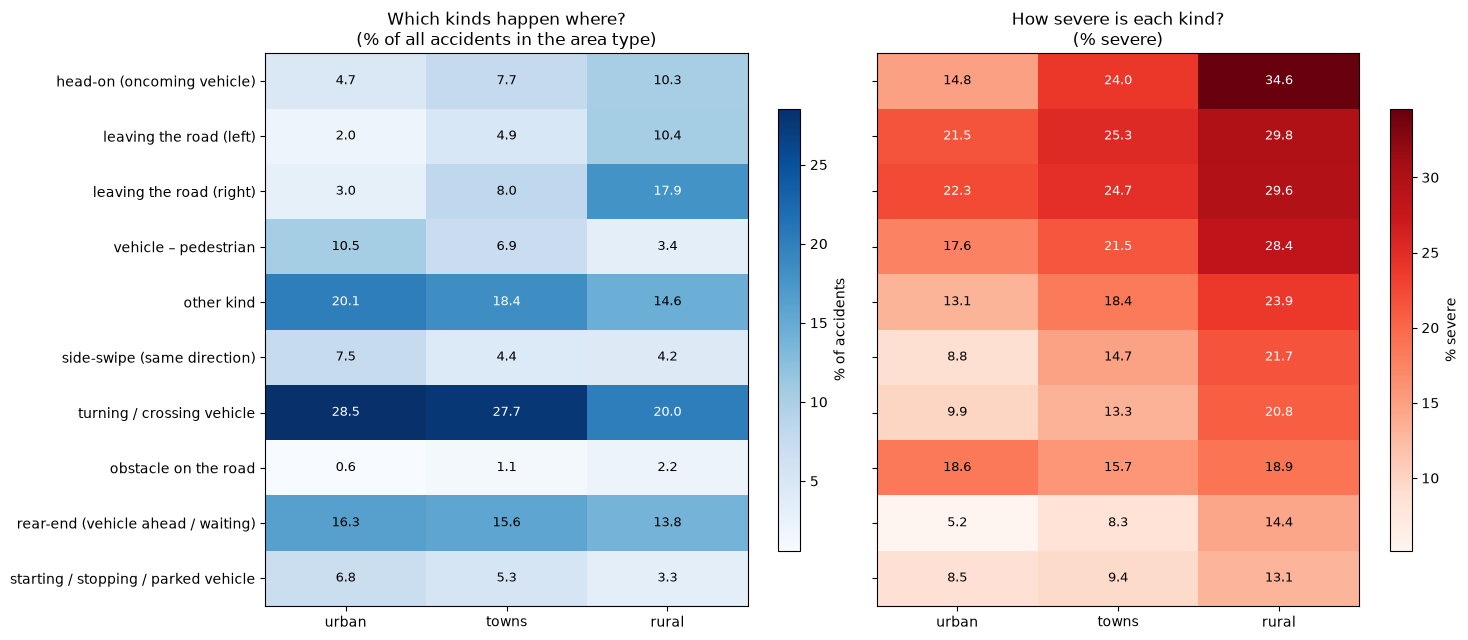

Severe %  urban: 11.3 | towns: 16.2 | rural: 24.3
Rural, if it had the urban mix of accident kinds: 21.8
-> of the 13.0-point gap, 2.5 points come from the mix of kinds, 10.5 points because the same kind is more severe in rural areas


area,urban (% of accidents),towns (% of accidents),rural (% of accidents),urban (% severe),towns (% severe),rural (% severe)
kind,,,,,,
head-on (oncoming vehicle),4.7,7.7,10.3,14.8,24.0,34.6
leaving the road (left),2.0,4.9,10.4,21.5,25.3,29.8
leaving the road (right),3.0,8.0,17.9,22.3,24.7,29.6
vehicle – pedestrian,10.5,6.9,3.4,17.6,21.5,28.4
other kind,20.1,18.4,14.6,13.1,18.4,23.9
side-swipe (same direction),7.5,4.4,4.2,8.8,14.7,21.7
turning / crossing vehicle,28.5,27.7,20.0,9.9,13.3,20.8
obstacle on the road,0.6,1.1,2.2,18.6,15.7,18.9
rear-end (vehicle ahead / waiting),16.3,15.6,13.8,5.2,8.3,14.4


In [23]:
import matplotlib.pyplot as plt

KIND_SHORT = {
    "Collision with another vehicle which turns into or crosses a road": "turning / crossing vehicle",
    "Accident of another kind": "other kind",
    "Collision with another vehicle moving ahead or waiting": "rear-end (vehicle ahead / waiting)",
    "Leaving the carriageway to the right": "leaving the road (right)",
    "Collision between vehicle and pedestrian": "vehicle – pedestrian",
    "Collision with another oncoming vehicle": "head-on (oncoming vehicle)",
    "Collision with another vehicle moving laterally in the same direction": "side-swipe (same direction)",
    "Collision with another vehicle which starts, stops or is stationary": "starting / stopping / parked vehicle",
    "Leaving the carriageway to the left": "leaving the road (left)",
    "Collision with an obstacle in the carriageway": "obstacle on the road",
}
AREA_SHORT = {"urban (densely populated)": "urban", "towns (medium)": "towns", "rural (sparsely populated)": "rural"}

# 1. Accidents with area type + short accident kind (analysis only - kind is NOT a model feature in Scenario C)
kind_area_df = acc_df[["ags", "severe", "accident_kind"]].copy()
kind_area_df["ags"] = kind_area_df["ags"].astype(str).str.zfill(8)
kind_area_df = kind_area_df.merge(city_urban_df[["ags", "area_type"]], on="ags", how="left")
kind_area_df["area"] = kind_area_df["area_type"].map(AREA_SHORT)
kind_area_df["kind"] = kind_area_df["accident_kind"].map(KIND_SHORT)
AREAS = ["urban", "towns", "rural"]

# 2. Mix: which kinds of accidents happen where? (% of accidents in each area type)
kind_mix_df = pd.crosstab(kind_area_df["kind"], kind_area_df["area"], normalize="columns")[AREAS] * 100
# 3. Severity: % severe per kind and area type
kind_severe_df = kind_area_df.pivot_table(index="kind", columns="area", values="severe", aggfunc="mean")[AREAS] * 100
kind_order = kind_severe_df["rural"].sort_values(ascending=False).index          # most severe kinds on top
kind_mix_df, kind_severe_df = kind_mix_df.loc[kind_order], kind_severe_df.loc[kind_order]

# 4. Two heatmaps side by side
fig, (ax_mix, ax_sev) = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
for ax, table, cmap, title, unit in [
        (ax_mix, kind_mix_df, "Blues", "Which kinds happen where?\n(% of all accidents in the area type)", "% of accidents"),
        (ax_sev, kind_severe_df, "Reds", "How severe is each kind?\n(% severe)", "% severe")]:
    image = ax.imshow(table.values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(AREAS)), AREAS)
    ax.set_yticks(range(len(table)), table.index)
    ax.set_title(title)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            value = table.iloc[i, j]
            ax.text(j, i, f"{value:.1f}", ha="center", va="center", fontsize=9,
                    color="white" if value > table.values.max() * 0.6 else "black")
    fig.colorbar(image, ax=ax, label=unit, shrink=0.8)
plt.tight_layout()
plt.show()

# 5. Is rural more severe because of the MIX of kinds, or is every kind worse in rural areas?
#    Expected rural severe %, if rural areas had the same mix of kinds as urban areas:
actual_by_area = kind_area_df.groupby("area")["severe"].mean()[AREAS] * 100
rural_with_urban_mix = (kind_severe_df["rural"] * kind_mix_df["urban"] / 100).sum()
print(f"Severe %  urban: {actual_by_area['urban']:.1f} | towns: {actual_by_area['towns']:.1f} | rural: {actual_by_area['rural']:.1f}")
print(f"Rural, if it had the urban mix of accident kinds: {rural_with_urban_mix:.1f}")
gap = actual_by_area["rural"] - actual_by_area["urban"]
print(f"-> of the {gap:.1f}-point gap, {actual_by_area['rural'] - rural_with_urban_mix:.1f} points come from the mix of kinds, "
      f"{rural_with_urban_mix - actual_by_area['urban']:.1f} points because the same kind is more severe in rural areas")

kind_mix_df.round(1).join(kind_severe_df.round(1), lsuffix=" (% of accidents)", rsuffix=" (% severe)")

young states  : Hamburg, Bremen, Berlin
middle states : Schleswig-Holstein, Niedersachsen, Nordrhein-Westfalen, Hessen, Rheinland-Pfalz, Baden-Württemberg, Bayern
old states    : Saarland, Brandenburg, Mecklenburg-Vorpommern, Sachsen, Sachsen-Anhalt, Thüringen


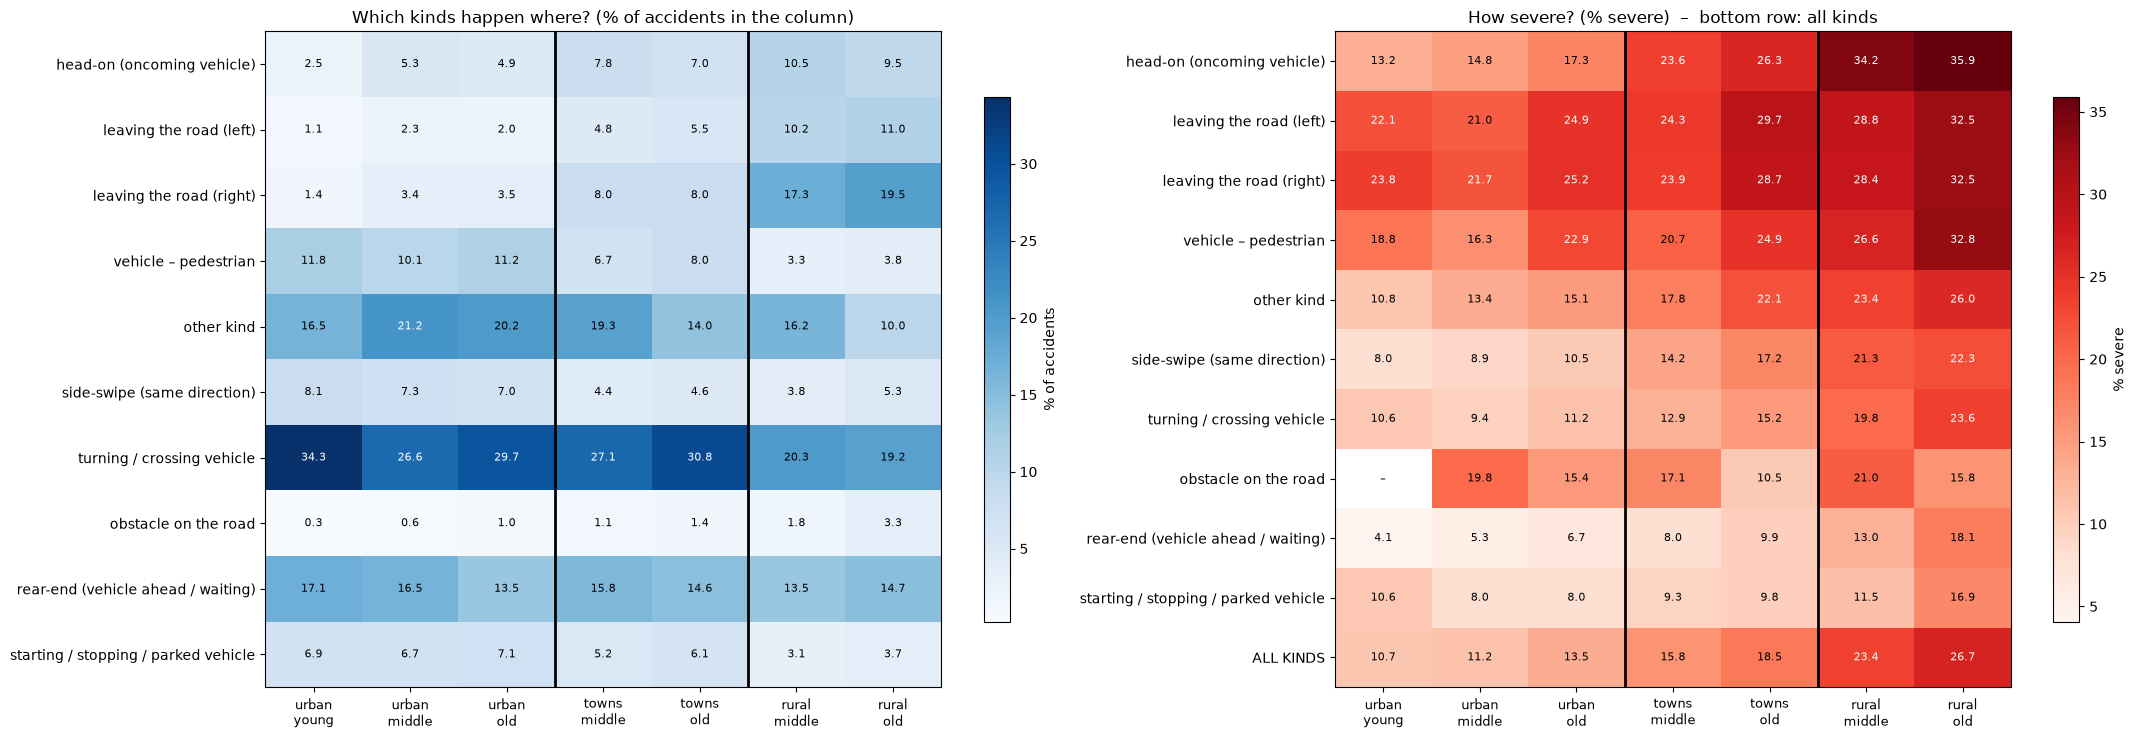

area_age,urban\nyoung,urban\nmiddle,urban\nold,towns\nmiddle,towns\nold,rural\nmiddle,rural\nold
kind,,,,,,,
head-on (oncoming vehicle),13.2,14.8,17.3,23.6,26.3,34.2,35.9
leaving the road (left),22.1,21.0,24.9,24.3,29.7,28.8,32.5
leaving the road (right),23.8,21.7,25.2,23.9,28.7,28.4,32.5
vehicle – pedestrian,18.8,16.3,22.9,20.7,24.9,26.6,32.8
other kind,10.8,13.4,15.1,17.8,22.1,23.4,26.0
side-swipe (same direction),8.0,8.9,10.5,14.2,17.2,21.3,22.3
turning / crossing vehicle,10.6,9.4,11.2,12.9,15.2,19.8,23.6
obstacle on the road,NaN,19.8,15.4,17.1,10.5,21.0,15.8
rear-end (vehicle ahead / waiting),4.1,5.3,6.7,8.0,9.9,13.0,18.1


In [24]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Group the 16 states by age profile (share of population aged 67+)
AGE_GROUP_LIMITS = [0, 19, 22, 100]                     # % aged 67+: <19 young, 19-22 middle, >22 old
AGE_GROUP_NAMES = ["young states", "middle states", "old states"]
state_age_group = pd.cut(pop_states_df.set_index("ULAND")["senior_drivers_67_plus_pct"],
                         bins=AGE_GROUP_LIMITS, labels=AGE_GROUP_NAMES).astype(str)
for group in AGE_GROUP_NAMES:
    members = pop_states_df.set_index("ULAND").loc[state_age_group == group, "state"].tolist()
    print(f"{group:14s}: {', '.join(members)}")

# 2. Every accident gets: area type + age group of its state + short accident kind
kind_age_df = kind_area_df.copy()
kind_age_df["state"] = acc_df["state"].to_numpy()                      # same row order as acc_df
kind_age_df["age_group"] = kind_age_df["state"].map(state_age_group)
kind_age_df["area_age"] = kind_age_df["area"] + "\n" + kind_age_df["age_group"].str.replace(" states", "")
COLUMN_ORDER = [f"{area}\n{age}" for area in AREAS for age in ["young", "middle", "old"]]
COLUMN_ORDER = [c for c in COLUMN_ORDER if c in set(kind_age_df["area_age"])]   # young states have no towns / rural

# 3. Mix and severity per kind, for every area type x age group (cells with < 100 accidents are hidden)
MIN_ACCIDENTS = 100
age_counts = pd.crosstab(kind_age_df["kind"], kind_age_df["area_age"])[COLUMN_ORDER].loc[kind_order]
age_mix_df = (age_counts / age_counts.sum() * 100)
age_severe_df = (kind_age_df.pivot_table(index="kind", columns="area_age", values="severe", aggfunc="mean")
                 [COLUMN_ORDER].loc[kind_order] * 100).where(age_counts >= MIN_ACCIDENTS)
age_all_kinds = kind_age_df.groupby("area_age")["severe"].mean()[COLUMN_ORDER] * 100

# 4. Two heatmaps: same accident kind + same area type -> do older states have more severe accidents?
fig, (ax_mix, ax_sev) = plt.subplots(1, 2, figsize=(22, 7.5))
for ax, table, cmap, title, unit in [
        (ax_mix, age_mix_df, "Blues", "Which kinds happen where? (% of accidents in the column)", "% of accidents"),
        (ax_sev, age_severe_df, "Reds", "How severe? (% severe)  –  bottom row: all kinds", "% severe")]:
    shown = table if ax is ax_mix else pd.concat([table, age_all_kinds.to_frame("ALL KINDS").T])
    image = ax.imshow(shown.values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(COLUMN_ORDER)), COLUMN_ORDER, fontsize=9)
    ax.set_yticks(range(len(shown)), shown.index)
    for boundary in [i - 0.5 for i in range(1, len(COLUMN_ORDER)) if COLUMN_ORDER[i].split("\n")[0] != COLUMN_ORDER[i - 1].split("\n")[0]]:
        ax.axvline(boundary, color="black", lw=2)                       # thick line between urban | towns | rural
    ax.set_title(title)
    for i in range(shown.shape[0]):
        for j in range(shown.shape[1]):
            value = shown.iloc[i, j]
            label = "–" if pd.isna(value) else f"{value:.1f}"
            ax.text(j, i, label, ha="center", va="center", fontsize=8,
                    color="white" if (not pd.isna(value) and value > np.nanmax(shown.values) * 0.6) else "black")
    fig.colorbar(image, ax=ax, label=unit, shrink=0.8)
plt.tight_layout()
plt.show()

age_severe_df.round(1)

young states  : Hamburg, Bremen, Berlin
middle states : Schleswig-Holstein, Niedersachsen, Nordrhein-Westfalen, Hessen, Rheinland-Pfalz, Baden-Württemberg, Bayern
old states    : Saarland, Brandenburg, Mecklenburg-Vorpommern, Sachsen, Sachsen-Anhalt, Thüringen


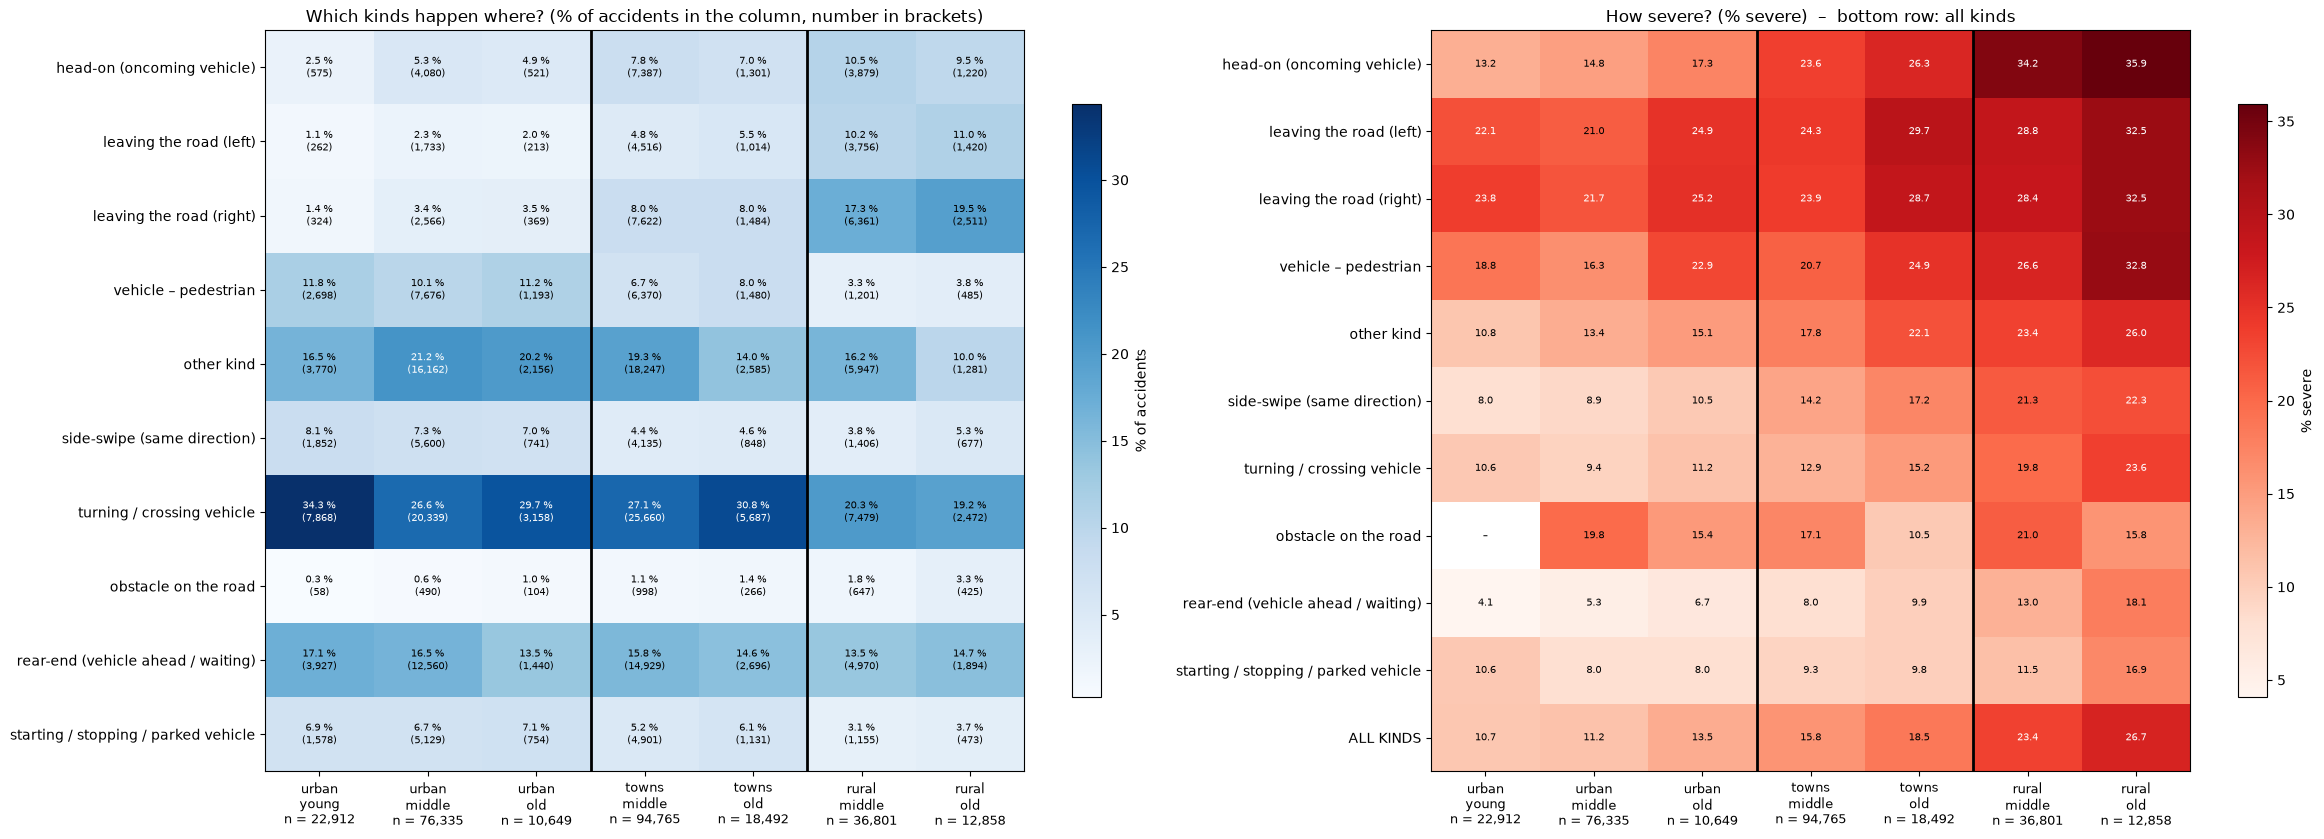

area_age,urban\nyoung,urban\nmiddle,urban\nold,towns\nmiddle,towns\nold,rural\nmiddle,rural\nold
kind,,,,,,,
head-on (oncoming vehicle),13.2,14.8,17.3,23.6,26.3,34.2,35.9
leaving the road (left),22.1,21.0,24.9,24.3,29.7,28.8,32.5
leaving the road (right),23.8,21.7,25.2,23.9,28.7,28.4,32.5
vehicle – pedestrian,18.8,16.3,22.9,20.7,24.9,26.6,32.8
other kind,10.8,13.4,15.1,17.8,22.1,23.4,26.0
side-swipe (same direction),8.0,8.9,10.5,14.2,17.2,21.3,22.3
turning / crossing vehicle,10.6,9.4,11.2,12.9,15.2,19.8,23.6
obstacle on the road,NaN,19.8,15.4,17.1,10.5,21.0,15.8
rear-end (vehicle ahead / waiting),4.1,5.3,6.7,8.0,9.9,13.0,18.1


In [25]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Group the 16 states by age profile (share of population aged 67+)
AGE_GROUP_LIMITS = [0, 19, 22, 100]                     # % aged 67+: <19 young, 19-22 middle, >22 old
AGE_GROUP_NAMES = ["young states", "middle states", "old states"]
state_age_group = pd.cut(pop_states_df.set_index("ULAND")["senior_drivers_67_plus_pct"],
                         bins=AGE_GROUP_LIMITS, labels=AGE_GROUP_NAMES).astype(str)
for group in AGE_GROUP_NAMES:
    members = pop_states_df.set_index("ULAND").loc[state_age_group == group, "state"].tolist()
    print(f"{group:14s}: {', '.join(members)}")

# 2. Every accident gets: area type + age group of its state + short accident kind
kind_age_df = kind_area_df.copy()
kind_age_df["state"] = acc_df["state"].to_numpy()                      # same row order as acc_df
kind_age_df["age_group"] = kind_age_df["state"].map(state_age_group)
kind_age_df["area_age"] = kind_age_df["area"] + "\n" + kind_age_df["age_group"].str.replace(" states", "")
COLUMN_ORDER = [f"{area}\n{age}" for area in AREAS for age in ["young", "middle", "old"]]
COLUMN_ORDER = [c for c in COLUMN_ORDER if c in set(kind_age_df["area_age"])]   # young states have no towns / rural

# 3. Mix and severity per kind, for every area type x age group (cells with < 100 accidents are hidden)
MIN_ACCIDENTS = 100
age_counts = pd.crosstab(kind_age_df["kind"], kind_age_df["area_age"])[COLUMN_ORDER].loc[kind_order]
age_mix_df = (age_counts / age_counts.sum() * 100)
age_severe_df = (kind_age_df.pivot_table(index="kind", columns="area_age", values="severe", aggfunc="mean")
                 [COLUMN_ORDER].loc[kind_order] * 100).where(age_counts >= MIN_ACCIDENTS)
age_all_kinds = kind_age_df.groupby("area_age")["severe"].mean()[COLUMN_ORDER] * 100

# Column labels with the number of accidents in each column
column_totals = age_counts.sum()
column_labels = [f"{col}\nn = {column_totals[col]:,}" for col in COLUMN_ORDER]

# 4. Two heatmaps: same accident kind + same area type -> do older states have more severe accidents?
fig, (ax_mix, ax_sev) = plt.subplots(1, 2, figsize=(24, 8.5))
for ax, table, cmap, title, unit in [
        (ax_mix, age_mix_df, "Blues", "Which kinds happen where? (% of accidents in the column, number in brackets)", "% of accidents"),
        (ax_sev, age_severe_df, "Reds", "How severe? (% severe)  –  bottom row: all kinds", "% severe")]:
    shown = table if ax is ax_mix else pd.concat([table, age_all_kinds.to_frame("ALL KINDS").T])
    image = ax.imshow(shown.values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(COLUMN_ORDER)), column_labels, fontsize=9)
    ax.set_yticks(range(len(shown)), shown.index)
    for boundary in [i - 0.5 for i in range(1, len(COLUMN_ORDER)) if COLUMN_ORDER[i].split("\n")[0] != COLUMN_ORDER[i - 1].split("\n")[0]]:
        ax.axvline(boundary, color="black", lw=2)                       # thick line between urban | towns | rural
    ax.set_title(title)
    for i in range(shown.shape[0]):
        for j in range(shown.shape[1]):
            value = shown.iloc[i, j]
            if pd.isna(value):
                label = "–"
            elif ax is ax_mix:
                label = f"{value:.1f} %\n({age_counts.iloc[i, j]:,})"         # share + number of accidents
            else:
                label = f"{value:.1f}"
            ax.text(j, i, label, ha="center", va="center", fontsize=7.5,
                    color="white" if (not pd.isna(value) and value > np.nanmax(shown.values) * 0.6) else "black")
    fig.colorbar(image, ax=ax, label=unit, shrink=0.8)
plt.tight_layout()
plt.show()

age_severe_df.round(1)